# Python Interview Lab — Part 2
## Client Segmentation, Transaction Behaviour, Migration & Regime Change

**End-to-end institutional-client analytics using simulated trades, unsupervised ML, time-series features and change detection.**

### The business question

> “How can we group institutional clients by the **way they trade**, see when clients change behaviour or **move between groups**, and distinguish an individual client transition from a market-wide regime change?”

For a senior quant/ML/AI engineering interview, demonstrate both modelling and operational judgment:

1. Define dynamic, point-in-time **client behaviour features** from transaction data.
2. Simulate distinct market states and evolving client preferences.
3. Discover groups without using synthetic ground-truth labels in training.
4. Track group **migration** through time, including temporary stress responses.
5. Detect changes using peer-normalised indicators, multivariate scores and CUSUM.
6. Evaluate false alarms against known simulated transitions, and propose production controls.

### Scope and expectations

- 60 invented institutional clients, 320 business days and thousands of simulated trades.
- Client styles: **income hedger**, **macro directional**, **high-activity liquidity taker**, **deleveraging / defensive**.
- Market regimes: **calm**, **risk-off**, **recovery**; client state transitions can occur inside each market state.
- Built-in charts, interview explanations, coding drills, tests and worked solutions.
- ~5–8 hours for a thorough pass; all data is generated in the notebook. No API keys or internet required.

**Important:** Client behavioural clustering is *descriptive*. A cluster is not a suitability approval, a protected-characteristic inference, or an investment recommendation. Ground-truth behavioural states exist **only** because we created synthetic data. They are not input features for the ML model.

## Roadmap

| Module | Technical interview focus | Visualisation |
|---|---|---|
| 1. Business and data contracts | client vs trade vs time granularity | data relationships |
| 2. Market and client simulation | stochastic processes, conditional behaviour | market regime panels, client timelines |
| 3. Feature engineering | `groupby`, aggregation, leakage controls | behavioural feature distributions |
| 4. Client grouping | standardisation, K-means, silhouette, PCA | cluster map, profiles |
| 5. Dynamic migrations | time-indexed clusters, transitions | migration matrix, client trajectories |
| 6. Regime/change detection | Jensen–Shannon, robust z-score, CUSUM | alert series and peer differences |
| 7. Evaluation | synthetic truth, lag, precision, regime bias | diagnostics and event study |
| 8. Interview practice | design, tests, live coding | solutions and mock case |

**Units:** USD notional and execution cost; 1 bp = 0.0001. `side = +1` is a buy, `side = -1` a sell. A 20-business-day **window** is a recent-behaviour summary, not a calendar month.

## 0 — Imports and reproducibility

Standard Jupyter/Anaconda packages: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`. We use deterministic random seeds and avoid extra libraries such as HDBSCAN or `ruptures` so the lab runs in a basic interview environment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.optimize import linear_sum_assignment
from scipy.stats import mannwhitneyu
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import RobustScaler

SEED = 1229
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(11,4),'axes.titlesize':12})
pd.set_option('display.max_columns',30)
pd.set_option('display.width',135)
print('pandas',pd.__version__,'| numpy',np.__version__,'| deterministic seed',SEED)

pandas 2.2.3 | numpy 2.3.5 | deterministic seed 1229


mkdir -p failed for path /root/.config/matplotlib: [Errno 30] Read-only file system: '/root/.config'
Matplotlib created a temporary cache directory at /tmp/matplotlib-n8zmbzr6 because there was an issue with the default path (/root/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1 — Data model: static identity, time-varying behaviour

There are **three distinct objects**:

| Object | Example fields | Grain |
|---|---|---|
| Client master | client ID, mandate, risk tier, region | One row per client or slowly changing version |
| Transactions | fill ID, timestamp, client, instrument, buy/sell, amount, slippage | One row per fill |
| Client window | 20-day turnover, buy/sell balance, product mix, costs | One client × one window |

**Key rule:** Never classify clients using next month's trades when assessing the client *today*. Materialised features must include `window_end` and an explicit as-of timestamp. A client can legitimately change its behavioural group **without** changing its legal client type or mandate.

### Simulated behaviour styles

- **Income hedger:** fewer, bond-heavy, smaller and mostly balanced trades.
- **Macro directional:** more futures/FX, moderate activity and directional flow.
- **Liquidity taker:** high-frequency trading, diversified products, higher urgency/slippage.
- **Defensive/deleveraging:** skewed toward sells/hedges, large tickets and elevated urgency.

We deliberately allow client-specific variation and overlapping distributions; otherwise clustering would be unrealistically trivial.

## 2 — Simulate two independent but interacting regime processes

1. **Market regime** is shared across clients: calm → risk-off → recovery.
2. **Client behavioural state** is individual: a client may shift style during stress, return to its prior style or permanently migrate.

The distinction matters: a market-wide increase in execution costs is not necessarily a change in one client's strategy. In the simulation, external stress affects everyone, while client transition episodes create *idiosyncratic* changes.

In [2]:
n_days=320
dates=pd.bdate_range('2025-01-02',periods=n_days)
day_idx=np.arange(n_days)
market_state=np.select([day_idx<110,day_idx<225],['Calm','Risk-off'],default='Recovery')
market_regime=pd.DataFrame({'date':dates,'day_idx':day_idx,'market_regime':market_state})

vol_scale=np.select([day_idx<110,day_idx<225],[1.,1.95],default=1.25)
drift=np.select([day_idx<110,day_idx<225],[.00035,-.00070],default=.00065)
equity_returns=drift+rng.normal(size=n_days)*.0075*vol_scale
rate_change_bp=rng.normal(size=n_days)*4.0*vol_scale+np.where(market_state=='Risk-off',.26,-.06)
credit_change_bp=rng.normal(size=n_days)*2.6*vol_scale+np.where(market_state=='Risk-off',.45,-.12)
stress_level=np.where(market_state=='Risk-off',.83,np.where(market_state=='Recovery',.36,.13))
stress_level=np.clip(stress_level+rng.normal(0,.08,n_days),0,1)
market_regime['equity_return']=equity_returns
market_regime['equity_index']=5000*np.cumprod(1+equity_returns)
market_regime['rates_change_bp']=rate_change_bp
market_regime['credit_change_bp']=credit_change_bp
market_regime['stress_index']=stress_level
market_regime['rolling_20d_vol']=pd.Series(equity_returns).rolling(20).std().to_numpy()*np.sqrt(252)*100
market_regime['window_id']=market_regime.day_idx//20
display(market_regime.head())

,date,day_idx,market_regime,equity_return,equity_index,rates_change_bp,credit_change_bp,stress_index,rolling_20d_vol,window_id
0,2025-01-02,0,Calm,0.004241,5021.206594,-0.343457,0.582651,0.167695,NaN,0
1,2025-01-03,1,Calm,0.009202,5067.411587,-1.578760,1.529956,0.194008,NaN,0
2,2025-01-06,2,Calm,0.005641,5095.997397,-1.136116,-7.707491,0.193469,NaN,0
3,2025-01-07,3,Calm,-0.001831,5086.665219,5.535698,-2.766686,0.178839,NaN,0
4,2025-01-08,4,Calm,-0.005249,5059.967114,6.447592,-1.128908,0.272543,NaN,0


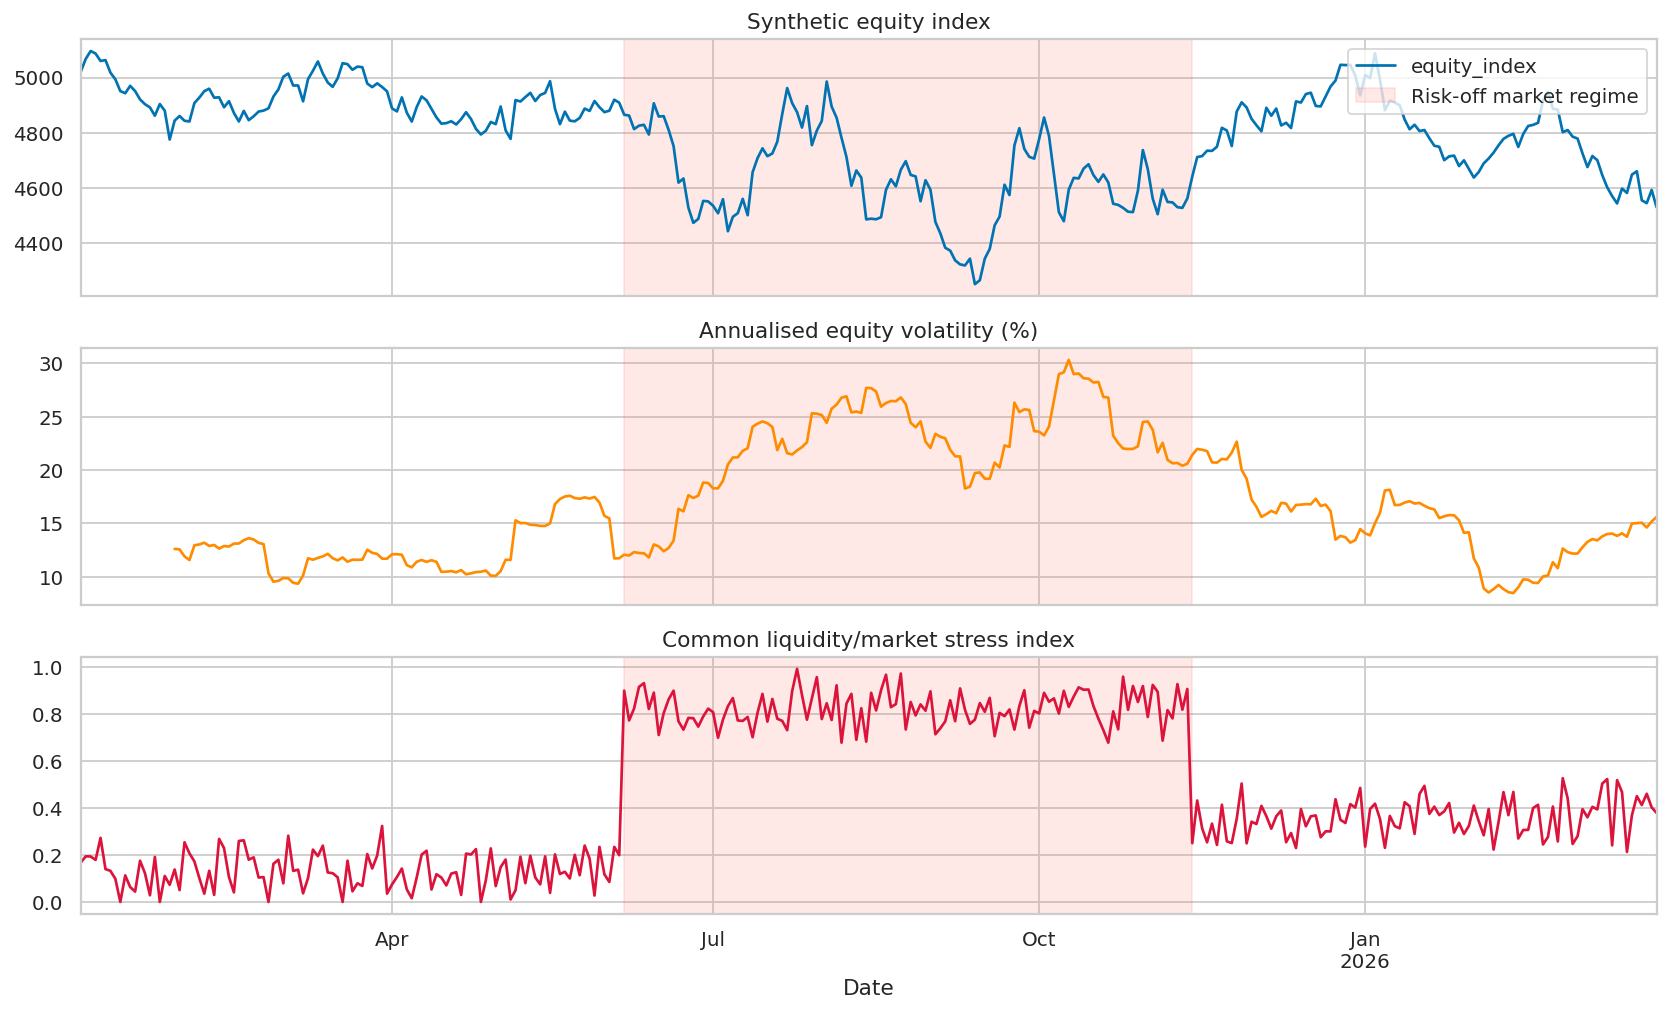

In [3]:
fig,axes=plt.subplots(3,1,figsize=(13,8),sharex=True)
market_regime.plot(x='date',y='equity_index',ax=axes[0],legend=False,title='Synthetic equity index')
market_regime.plot(x='date',y='rolling_20d_vol',ax=axes[1],color='darkorange',legend=False,title='Annualised equity volatility (%)')
market_regime.plot(x='date',y='stress_index',ax=axes[2],color='crimson',legend=False,title='Common liquidity/market stress index')
for ax in axes:
    ax.axvspan(dates[110],dates[225],color='salmon',alpha=.17,label='Risk-off market regime')
axes[0].legend(loc='upper right');axes[2].set_xlabel('Date');plt.tight_layout();plt.show()

### Client master and behavioural parameters

These profiles generate trade behaviour; only the simulated client master and transactions would be visible in a real system. **Hidden behavioural state** is retained exclusively for the later evaluation section.

In [4]:
N_CLIENTS=60
client_ids=[f'C{i:03}' for i in range(1,N_CLIENTS+1)]
BEHAVIOURS=['Income hedger','Macro directional','Liquidity taker','Defensive/deleveraging']
ASSETS=['BOND','FUTURE','FX','CREDIT']
INST_BY_ASSET={
  'BOND':['GILT5','GOVT10'],
  'FUTURE':['US_EQ_FUT','UK_EQ_FUT'],
  'FX':['GBPUSD_FWD','EURUSD_FWD'],
  'CREDIT':['IG_CREDIT','HY_CREDIT']}

profile_params={
 'Income hedger':{'intensity':.75,'mix':[.56,.10,.20,.14],'buy_prob':.53,'ticket_m':4.5,'urgency':.23},
 'Macro directional':{'intensity':1.65,'mix':[.10,.42,.39,.09],'buy_prob':.64,'ticket_m':8.0,'urgency':.48},
 'Liquidity taker':{'intensity':3.20,'mix':[.19,.28,.26,.27],'buy_prob':.51,'ticket_m':3.2,'urgency':.75},
 'Defensive/deleveraging':{'intensity':2.15,'mix':[.13,.19,.48,.20],'buy_prob':.17,'ticket_m':10.5,'urgency':.90}}

baseline=rng.choice(BEHAVIOURS[:3],N_CLIENTS,p=[.37,.36,.27])
client_master=pd.DataFrame({
 'client_id':client_ids,
 'client_type':rng.choice(['Pension','Asset manager','Hedge fund','Insurance','Corporate treasury'],N_CLIENTS),
 'mandate_risk_tier':rng.choice(['Low','Medium','High'],N_CLIENTS,p=[.28,.40,.32]),
 'region':rng.choice(['UK','Europe','US'],N_CLIENTS,p=[.45,.35,.20]),
 'size_multiplier':rng.lognormal(0,.23,N_CLIENTS),
 'activity_multiplier':rng.lognormal(0,.25,N_CLIENTS),
 'slippage_bias_bp':rng.normal(0,.80,N_CLIENTS)})
display(client_master.head(8))

,client_id,client_type,mandate_risk_tier,region,size_multiplier,activity_multiplier,slippage_bias_bp
0,C001,Insurance,Medium,UK,0.876310,1.071797,-0.301549
1,C002,Insurance,High,Europe,1.280095,1.064445,-0.460182
2,C003,Hedge fund,Medium,US,1.026217,0.659576,-1.252140
3,C004,Corporate treasury,Low,Europe,0.850068,0.969988,1.593082
4,C005,Corporate treasury,Medium,UK,0.964821,1.011410,0.582716
5,C006,Corporate treasury,Low,Europe,1.355386,0.746737,-0.272717
6,C007,Corporate treasury,Medium,UK,1.335094,1.189215,-0.162159
7,C008,Corporate treasury,Low,Europe,1.177049,1.152631,1.436333


### Inject client transitions

Every client has at least one **known, synthetic change episode**. Some transitions lead to a defensive phase during market stress; others reflect a change in strategy unrelated to common stress. Most change episodes last 45–90 trading days. A subset have a second, persistent shift during recovery.

This is intentional so we can score detection methods. **Do not put `true_state`, `switch_day`, or transition-event tables in model features.**

In [5]:
state=np.empty((N_CLIENTS,n_days),dtype=object)
events=[]
for c,cid in enumerate(client_ids):
    state[c,:]=baseline[c]
    start=int(rng.integers(105,196))
    duration=int(rng.integers(45,91))
    end=min(start+duration,n_days)
    if rng.random()<.56:
        changed='Defensive/deleveraging'
    else:
        changed=str(rng.choice([x for x in BEHAVIOURS if x!=baseline[c]]))
    state[c,start:end]=changed
    events.append((cid,start,end,str(baseline[c]),changed,'temporary'))
    if rng.random()<.28:
        next_day=int(rng.integers(248,290))
        next_state=str(rng.choice([x for x in BEHAVIOURS if x!=state[c,next_day]]))
        old=str(state[c,next_day])
        state[c,next_day:]=next_state
        events.append((cid,next_day,n_days,old,next_state,'persistent'))

events=pd.DataFrame(events,columns=['client_id','start_day','end_day','from_state','to_state','kind'])
events['start_date']=events.start_day.map(lambda i:dates[i])
hidden_states=pd.DataFrame(state.T,index=dates,columns=client_ids)
print('Simulated change events:',len(events),'| clients with events:',events.client_id.nunique())
display(events.head(8))

Simulated change events: 83 | clients with events: 60


,client_id,start_day,end_day,from_state,to_state,kind,start_date
0,C001,130,178,Liquidity taker,Defensive/deleveraging,temporary,2025-07-03
1,C001,251,320,Liquidity taker,Defensive/deleveraging,persistent,2025-12-19
2,C002,124,208,Income hedger,Liquidity taker,temporary,2025-06-25
3,C003,108,188,Macro directional,Defensive/deleveraging,temporary,2025-06-03
4,C003,285,320,Macro directional,Defensive/deleveraging,persistent,2026-02-05
5,C004,172,242,Liquidity taker,Macro directional,temporary,2025-09-01
6,C005,182,245,Macro directional,Defensive/deleveraging,temporary,2025-09-15
7,C005,264,320,Macro directional,Defensive/deleveraging,persistent,2026-01-07


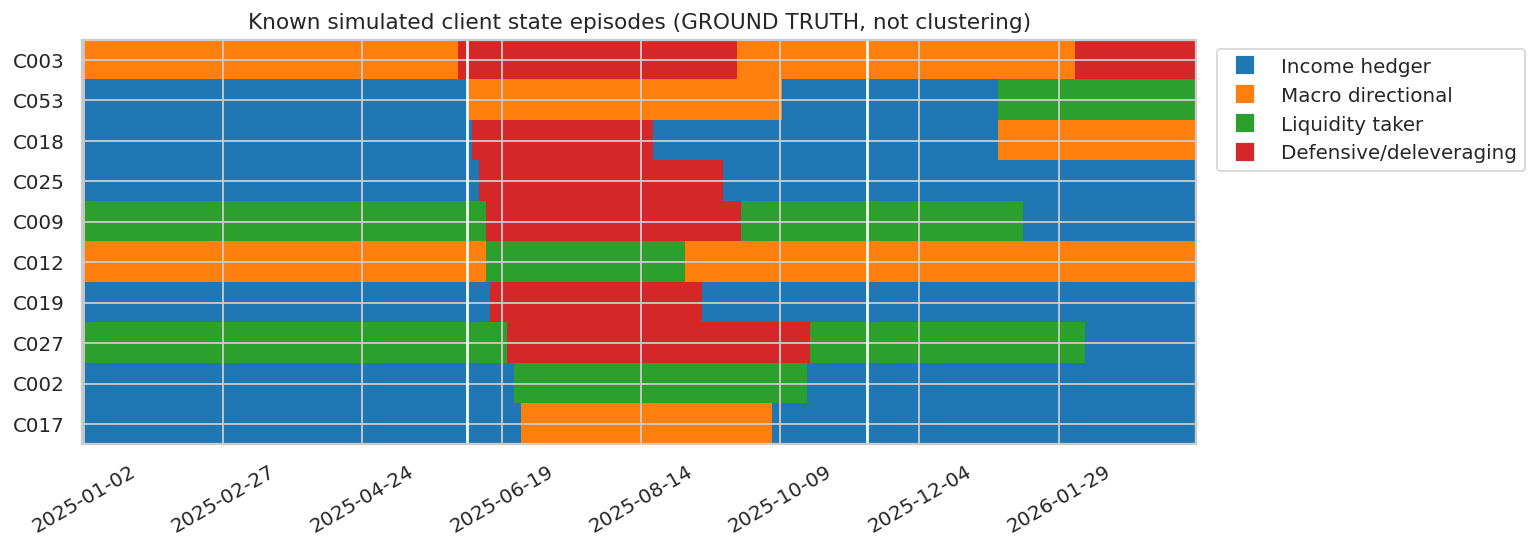

In [6]:
# A timeline of *latent simulation truth*. In real markets this would be unobserved.
state_number={s:i for i,s in enumerate(BEHAVIOURS)}
example_ids=events.sort_values('start_day').client_id.drop_duplicates().head(10).tolist()
latent_grid=np.array([[state_number[x] for x in hidden_states[c]] for c in example_ids])
fig,ax=plt.subplots(figsize=(12,4.4))
im=ax.imshow(latent_grid,aspect='auto',interpolation='nearest',cmap='tab10',vmin=0,vmax=9)
ax.set(yticks=np.arange(len(example_ids)),yticklabels=example_ids,
       xticks=np.arange(0,n_days,40),xticklabels=[str(dates[k].date()) for k in range(0,n_days,40)],
       title='Known simulated client state episodes (GROUND TRUTH, not clustering)')
ax.axvline(110,color='white',lw=1.5);ax.axvline(225,color='white',lw=1.5)
ax.tick_params(axis='x',rotation=30)
legend_handles=[plt.Line2D([0],[0],marker='s',color='w',markerfacecolor=plt.cm.tab10(i/10),
                           markersize=11,label=s) for s,i in state_number.items()]
ax.legend(handles=legend_handles,bbox_to_anchor=(1.01,1),loc='upper left')
plt.tight_layout();plt.show()

## 3 — Generate transaction events conditional on market and client state

The generator below resembles an event stream: on each day, each client places a stochastic number of filled trades. Product mix, size, direction, urgency and slippage depend on **client behaviour** and **market stress**. There is some overlapping variation, so inference is imperfect.

Interview prompt: explain the difference between **data-generation assumptions** and learned relationships. Here, slippage partly depends on urgency and common stress because we explicitly simulated that mechanism. Such an association is not proof of causation in real fills.

In [7]:
tx_records=[]
tx_num=0
for day,dt in enumerate(dates):
    common_stress=float(stress_level[day])
    for c,cid in enumerate(client_ids):
        behaviour=str(state[c,day])
        p=profile_params[behaviour]
        lam=p['intensity']*float(client_master.loc[c,'activity_multiplier'])
        lam*=1+.14*common_stress
        n_today=int(rng.poisson(lam))
        for _ in range(n_today):
            tx_num+=1
            asset=str(rng.choice(ASSETS,p=p['mix']))
            instrument=str(rng.choice(INST_BY_ASSET[asset]))
            side=1 if rng.random()<p['buy_prob'] else -1
            # Normalised random ticket: sizable dispersion without extreme outliers.
            ticket=float(np.clip(p['ticket_m']*client_master.loc[c,'size_multiplier']*
                                  rng.lognormal(-.10,.52),.30,60.0))*1e6
            liquidity=float(np.clip(1-.40*common_stress-.24*p['urgency']+
                                    rng.normal(0,.12),.08,.99))
            urgency=float(np.clip(p['urgency']+.12*common_stress+rng.normal(0,.11),.01,.99))
            slippage=max(.10,1.1+5.5*common_stress+5.2*urgency+
                         2.0*(1-liquidity)+client_master.loc[c,'slippage_bias_bp']+
                         rng.normal(0,1.8))
            spread=max(.20,.95+2.8*common_stress+1.9*(1-liquidity)+rng.normal(0,.35))
            partial=int(rng.random()<.07+.27*urgency+.07*common_stress)
            impact_bp=(spread+slippage)
            time_in_day=int(rng.integers(0,7*60*60))
            timestamp=dt+pd.Timedelta(hours=8,seconds=time_in_day)
            tx_records.append((f'F{tx_num:07}',timestamp,dt,day,day//20,cid,
                               instrument,asset,side,ticket,liquidity,urgency,
                               slippage,spread,partial,impact_bp,ticket*impact_bp/10000,
                               market_state[day],behaviour))

trades=pd.DataFrame(tx_records,columns=['fill_id','timestamp','date','day_idx','window_id',
 'client_id','instrument','asset_class','side','notional_usd','liquidity_score','urgency',
 'slippage_bps','spread_bps','partial_fill','execution_cost_bps','execution_cost_usd',
 'true_market_regime','true_client_state'])
trades['signed_notional_usd']=trades.side*trades.notional_usd
trades['sell_indicator']=(trades.side==-1).astype(int)
print('Simulated fills:',f'{len(trades):,}','| clients:',trades.client_id.nunique(),
      '| instruments:',trades.instrument.nunique())
display(trades[['fill_id','timestamp','client_id','asset_class','side','notional_usd',
                'slippage_bps','partial_fill']].head())

Simulated fills: 37,492 | clients: 60 | instruments: 8


,fill_id,timestamp,client_id,asset_class,side,notional_usd,slippage_bps,partial_fill
0,F0000001,2025-01-02 14:52:31,C001,BOND,1,4.523606e+06,6.424727,1
1,F0000002,2025-01-02 10:13:41,C001,FUTURE,-1,2.345203e+06,7.062240,1
2,F0000003,2025-01-02 10:30:26,C001,BOND,1,2.097856e+06,8.502180,0
3,F0000004,2025-01-02 13:16:56,C001,FUTURE,-1,3.158722e+06,7.232052,1
4,F0000005,2025-01-02 13:54:57,C002,BOND,-1,5.106809e+06,0.463298,0


### Data-quality contract

Write the checks before constructing features. A duplicate fill, an invalid sign or a future-dated quote can materially distort clustering.

,issues
duplicate_fill_ids,0
missing_client,0
bad_side,0
nonpositive_notional,0
invalid_liquidity,0
negative_cost,0
unknown_instrument,0


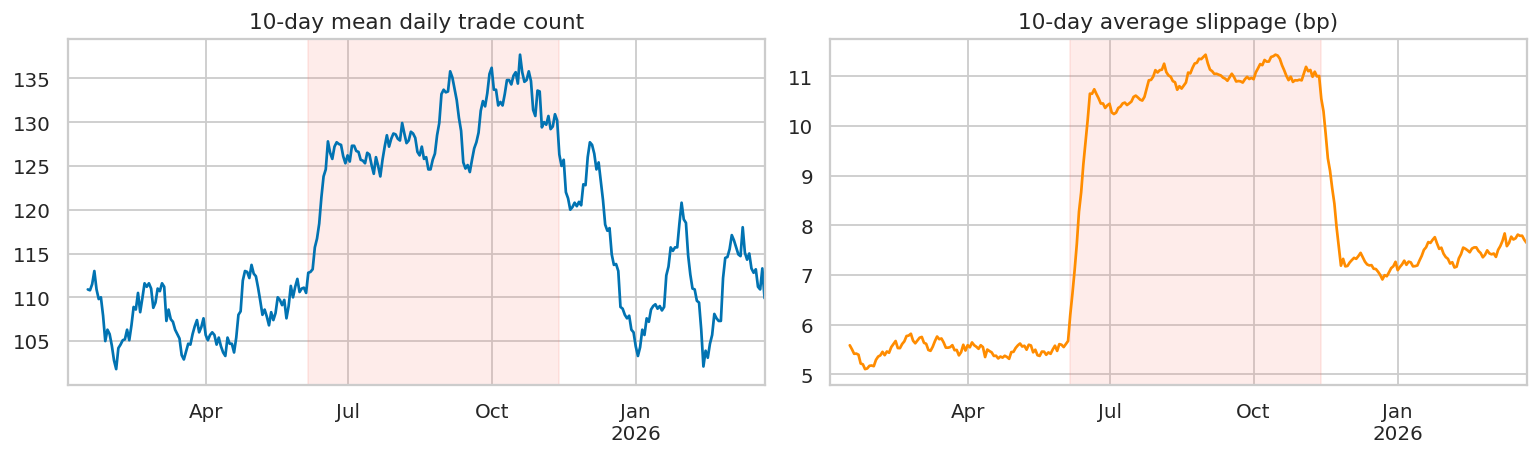

In [8]:
def transaction_quality_checks(df:pd.DataFrame)->dict:
    return {
       'duplicate_fill_ids':int(df.fill_id.duplicated().sum()),
       'missing_client':int(df.client_id.isna().sum()),
       'bad_side':int((~df.side.isin([-1,1])).sum()),
       'nonpositive_notional':int((df.notional_usd<=0).sum()),
       'invalid_liquidity':int((~df.liquidity_score.between(0,1)).sum()),
       'negative_cost':int((df.execution_cost_bps<0).sum()),
       'unknown_instrument':int((~df.instrument.isin(sum(INST_BY_ASSET.values(),[]))).sum()),
    }

quality=transaction_quality_checks(trades)
display(pd.Series(quality,name='issues').to_frame())
assert all(v==0 for v in quality.values())
assert (trades.timestamp.dt.normalize()==trades.date).all()

daily_activity=(trades.groupby('date').agg(fills=('fill_id','count'),
                    notional_usd=('notional_usd','sum'),mean_slippage=('slippage_bps','mean'))
                .reindex(dates,fill_value=0))
fig,ax=plt.subplots(1,2,figsize=(12,3.7))
daily_activity.fills.rolling(10).mean().plot(ax=ax[0],title='10-day mean daily trade count')
daily_activity.mean_slippage.rolling(10).mean().plot(ax=ax[1],color='darkorange',title='10-day average slippage (bp)')
for a in ax: a.axvspan(dates[110],dates[225],alpha=.15,color='salmon')
fig.tight_layout();plt.show()

## 4 — Turn trades into client features

Grouping individual trades can be noisy. Aggregate using a **20-day trailing behavioural view** here represented by consecutive, non-overlapping 20-business-day windows. Non-overlapping windows simplify evaluation and migration counts; a real daily feature store may update rolling windows at each new fill.

Features to consider:

| Category | Feature | Interpretation |
|---|---|---|
| Activity | fills/day, notional/day | intensity and scale |
| Product preference | fraction of notional in bond/future/FX/credit | strategy mix |
| Direction | sell share, absolute net-flow ratio | deleveraging/directional imbalance |
| Execution | notional-weighted slippage, partial-fill share | urgency and market quality |
| Concentration | instrument Herfindahl index (HHI) | how concentrated product usage is |
| External context | market stress at window end | avoid confusing systemic vs client drift |

**Leakage rule:** Do not include `true_client_state`, future transactions, subsequent P&L or synthetic switch dates in the clustering feature set.

In [9]:
# Base client×window aggregation. Explicitly weight bp metrics by USD notional.
keys=['client_id','window_id']
base=(trades.groupby(keys,sort=True).agg(
   fills=('fill_id','count'),
   turnover_usd=('notional_usd','sum'),
   mean_ticket_usd=('notional_usd','mean'),
   signed_flow_usd=('signed_notional_usd','sum'),
   sell_share=('sell_indicator','mean'),
   partial_share=('partial_fill','mean'),
   urgency_mean=('urgency','mean'),
   cost_usd=('execution_cost_usd','sum')).reset_index())
base['fills_per_day']=base.fills/20
base['turnover_musd_per_day']=base.turnover_usd/1e6/20
base['avg_ticket_musd']=base.mean_ticket_usd/1e6
base['abs_flow_imbalance']=(base.signed_flow_usd/base.turnover_usd).abs()
base['weighted_cost_bps']=base.cost_usd/base.turnover_usd*10000

# Value-based product shares. Value weights reflect capital usage, not trade count.
product_values=trades.pivot_table(index=keys,columns='asset_class',
        values='notional_usd',aggfunc='sum',fill_value=0)
product_shares=product_values.div(product_values.sum(axis=1),axis=0)
product_shares=product_shares.reindex(columns=ASSETS,fill_value=0)
product_shares.columns=[f'share_{x.lower()}' for x in product_shares.columns]
product_shares=product_shares.reset_index()

# HHI: sum squared instrument notional shares; ~1 concentrated, smaller = diversified.
instrument_volume=trades.groupby(keys+['instrument']).notional_usd.sum()
instrument_weight=instrument_volume/instrument_volume.groupby(level=keys).transform('sum')
instrument_hhi=instrument_weight.pow(2).groupby(level=keys).sum().rename('instrument_hhi').reset_index()

client_windows=(base.merge(product_shares,on=keys,validate='one_to_one')
                .merge(instrument_hhi,on=keys,validate='one_to_one'))
window_dates=(market_regime.groupby('window_id').agg(
   window_start=('date','min'),window_end=('date','max'),
   common_stress=('stress_index','mean'),
   window_market_regime=('market_regime',lambda x:x.mode().iloc[0])))
client_windows=client_windows.merge(window_dates,on='window_id',validate='many_to_one')

assert np.allclose(client_windows[[f'share_{x.lower()}' for x in ASSETS]].sum(axis=1),1)
assert client_windows[['client_id','window_id']].duplicated().sum()==0
print('Client-window records:',len(client_windows),'| windows:',client_windows.window_id.nunique())
display(client_windows.head(6))

Client-window records: 960 | windows: 16


,client_id,window_id,fills,turnover_usd,mean_ticket_usd,signed_flow_usd,sell_share,partial_share,urgency_mean,cost_usd,...,weighted_cost_bps,share_bond,share_future,share_fx,share_credit,instrument_hhi,window_start,window_end,common_stress,window_market_regime
0,C001,0,56,1.580771e+08,2.822805e+06,2.519916e+07,0.464286,0.267857,0.736102,119450.033035,...,7.556442,0.280755,0.250624,0.209797,0.258823,0.136183,2025-01-02,2025-01-29,0.121837,Calm
1,C001,1,74,2.149172e+08,2.904287e+06,-4.817077e+07,0.581081,0.337838,0.761166,174562.578382,...,8.122316,0.145254,0.258513,0.297398,0.298835,0.143265,2025-01-30,2025-02-26,0.144541,Calm
2,C001,2,67,1.867550e+08,2.787387e+06,1.143186e+07,0.492537,0.298507,0.767624,153945.316886,...,8.243172,0.216153,0.251307,0.232884,0.299657,0.138736,2025-02-27,2025-03-26,0.133634,Calm
3,C001,3,76,2.043530e+08,2.688855e+06,3.130363e+07,0.434211,0.289474,0.765029,158521.617837,...,7.757244,0.228146,0.221397,0.313754,0.236703,0.134317,2025-03-27,2025-04-23,0.125039,Calm
4,C001,4,70,2.030294e+08,2.900419e+06,-2.610522e+07,0.542857,0.285714,0.750978,147683.530431,...,7.273999,0.206311,0.363983,0.168052,0.261654,0.137319,2025-04-24,2025-05-21,0.121617,Calm
5,C001,5,82,2.496764e+08,3.044834e+06,3.988543e+06,0.536585,0.402439,0.818949,319972.191073,...,12.815477,0.239619,0.235218,0.250246,0.274918,0.130873,2025-05-22,2025-06-18,0.503099,Calm


### Visual inspection: does feature engineering capture heterogeneity?

Large and small clients are not interchangeable; compare **notional-normalised** activity and execution features and use robust scaling before K-means. We also inspect correlations to avoid letting redundant variables dominate Euclidean distance.

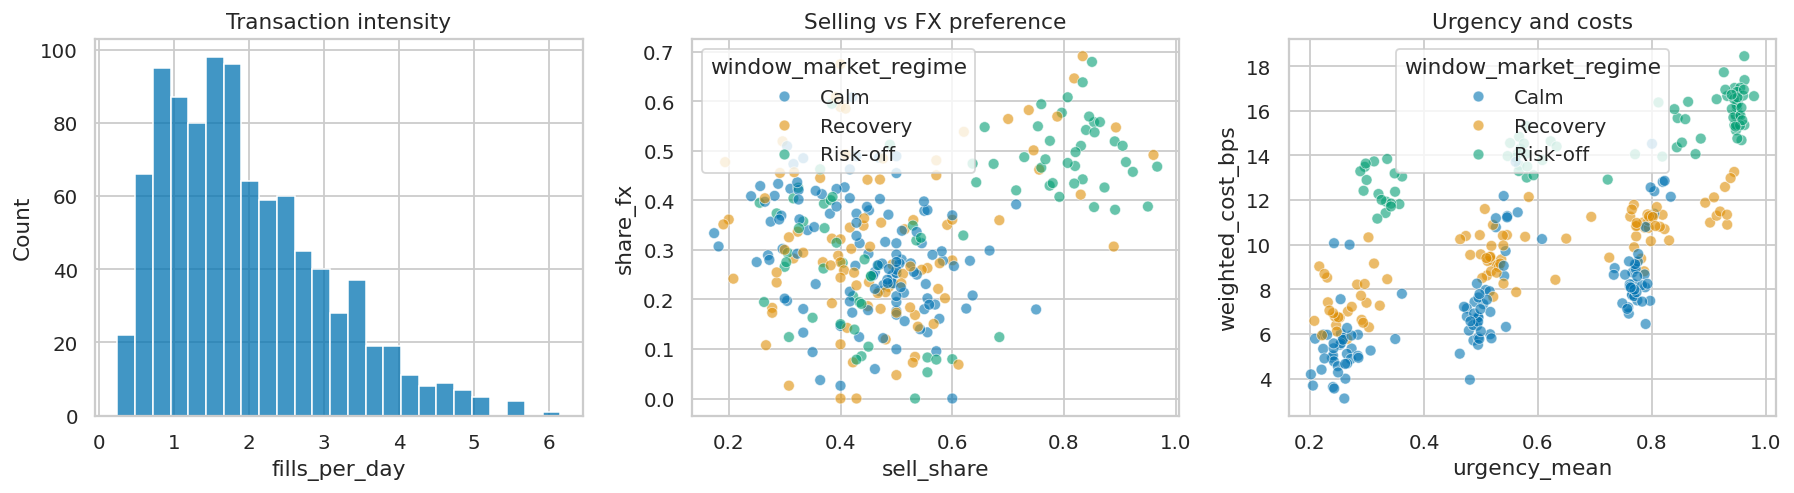

In [10]:
feature_cols=['fills_per_day','turnover_musd_per_day','avg_ticket_musd',
              'sell_share','abs_flow_imbalance','partial_share','urgency_mean',
              'weighted_cost_bps','instrument_hhi','share_bond','share_future',
              'share_fx','share_credit']
fig,ax=plt.subplots(1,3,figsize=(14,4))
sns.histplot(data=client_windows,x='fills_per_day',bins=25,ax=ax[0]);ax[0].set_title('Transaction intensity')
sns.scatterplot(data=client_windows.sample(300,random_state=SEED),
                x='sell_share',y='share_fx',hue='window_market_regime',
                alpha=.6,ax=ax[1]);ax[1].set_title('Selling vs FX preference')
sns.scatterplot(data=client_windows.sample(300,random_state=SEED),
                x='urgency_mean',y='weighted_cost_bps',
                hue='window_market_regime',alpha=.6,ax=ax[2]);ax[2].set_title('Urgency and costs')
fig.tight_layout();plt.show()

### Exercise A (15 min): create a point-in-time feature

Using only trades whose timestamp is **at or before** a decision timestamp:

1. Calculate each client's total 20-day trading notional and notional-weighted slippage.
2. Compute each client's buy/sell notional imbalance (not merely number of buys).
3. Find each client's top two instruments by notional.
4. Explain when a `groupby().apply()` is convenient and when a vectorised `groupby().agg()` is faster.

Write your solution below. Worked solutions are in Module 10.

In [11]:
# EXERCISE A — your own point-in-time features.
# cutoff = pd.Timestamp('2025-10-01 16:00')
# recent_trades = trades[(trades.timestamp<=cutoff) & ...]

## 5 — Segment clients using K-means (unsupervised)

This section is a **retrospective discovery** of behavioural groups, not prediction of a trade's P&L. We fit only on windows 0–10 and then apply the *same* fitted scaler and centroids to later windows 11–15 to demonstrate deployment without updating centroids from the future.

**How many clusters?** Compare silhouette scores for `k=2...6`, choose a workable `k`, and inspect whether each group has a coherent business interpretation. No clustering algorithm knows the “right” client categories.

We intentionally exclude common market-stress context from K-means because we are trying to group **client behaviour**, while later monitoring adjusts for common changes.

,k,silhouette,inertia
0,2,0.296,914.880
1,3,0.325,659.502
2,4,0.355,493.048
3,5,0.326,453.749
4,6,0.266,429.400


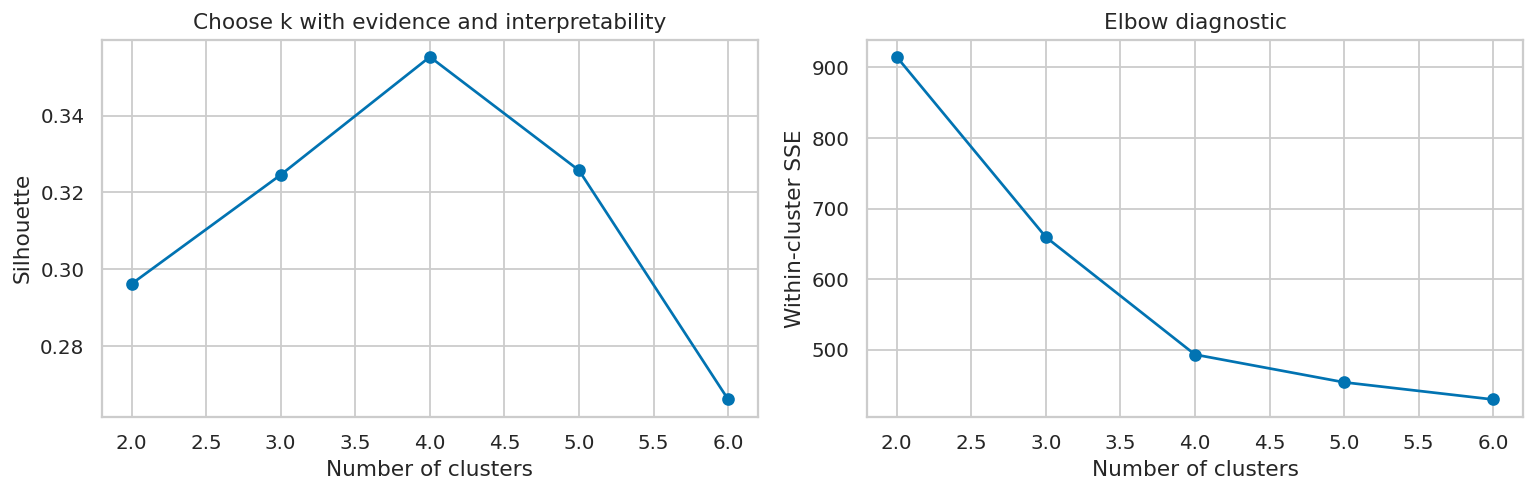

In [12]:
fit_mask=client_windows.window_id<=10
scaler=RobustScaler(quantile_range=(10,90))
X_fit=scaler.fit_transform(client_windows.loc[fit_mask,feature_cols])
X_all=scaler.transform(client_windows[feature_cols])

k_diagnostics=[]
for k in range(2,7):
    mdl=KMeans(n_clusters=k,n_init=15,random_state=SEED)
    labels=mdl.fit_predict(X_fit)
    k_diagnostics.append((k,silhouette_score(X_fit,labels),mdl.inertia_))
diagnostics=pd.DataFrame(k_diagnostics,columns=['k','silhouette','inertia'])
display(diagnostics.round(3))

K=4  # fixed for an interpretable four-group exercise; not necessarily score-optimal
kmeans=KMeans(n_clusters=K,n_init=25,random_state=SEED)
kmeans.fit(X_fit)
client_windows['segment']=kmeans.predict(X_all)
client_windows['segment_id']=client_windows.segment.map(lambda x:f'S{x}')

fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(diagnostics.k,diagnostics.silhouette,'o-');axs[0].set(xlabel='Number of clusters',ylabel='Silhouette',title='Choose k with evidence and interpretability')
axs[1].plot(diagnostics.k,diagnostics.inertia,'o-');axs[1].set(xlabel='Number of clusters',ylabel='Within-cluster SSE',title='Elbow diagnostic')
plt.tight_layout();plt.show()

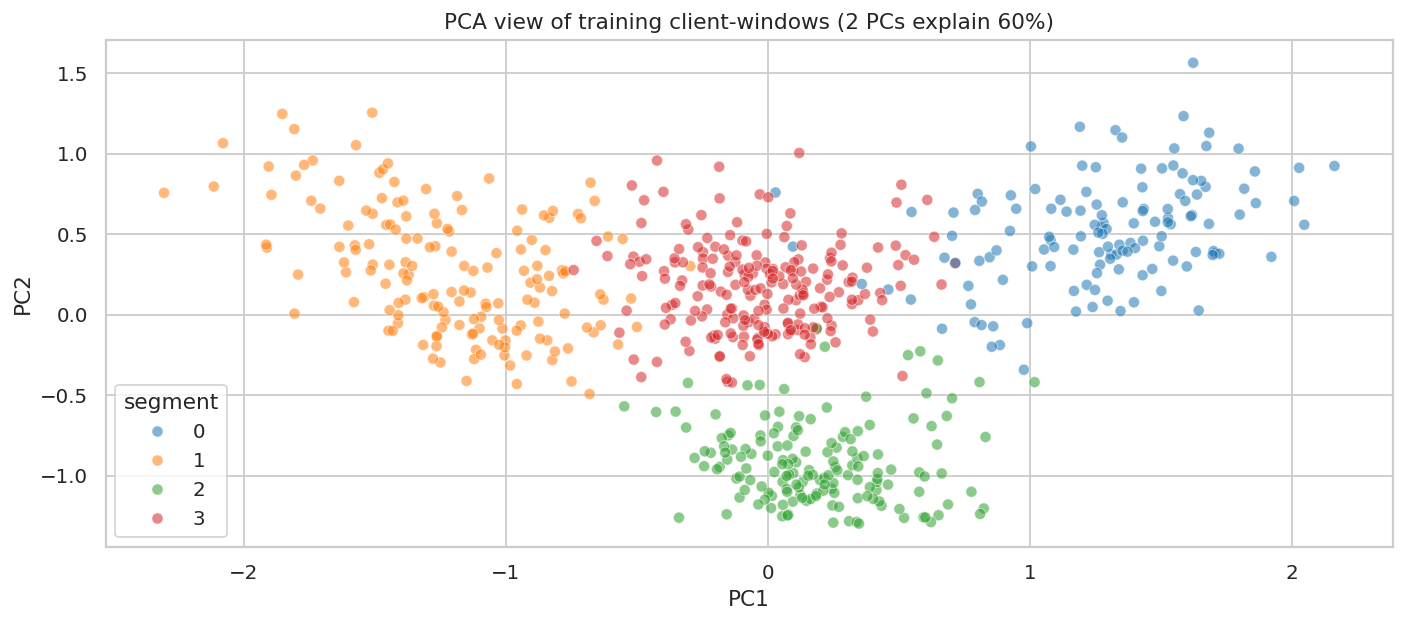

In [13]:
pca=PCA(n_components=2,random_state=SEED)
pca_coords=pca.fit_transform(X_fit)
fit_df=client_windows.loc[fit_mask,['client_id','window_id','segment']].copy()
fit_df['PC1']=pca_coords[:,0];fit_df['PC2']=pca_coords[:,1]
fig,ax=plt.subplots(figsize=(11,5))
sns.scatterplot(data=fit_df,x='PC1',y='PC2',hue='segment',
                palette='tab10',alpha=.55,s=38,ax=ax)
ax.set_title(f'PCA view of training client-windows (2 PCs explain {pca.explained_variance_ratio_.sum():.0%})')
plt.tight_layout();plt.show()

### Interpret clusters from real observed features

Cluster numbers (`S0`, `S1`, etc.) are arbitrary and may permute after retraining. **Do not assign business labels solely from the numeric ID.** Examine centroid profiles, representative clients, and stability. Descriptive names should be agreed with trading/sales/risk domain experts and versioned.

segment,0,1,2,3
fills_per_day,2.30,0.82,3.18,1.70
turnover_musd_per_day,25.72,4.17,10.72,12.90
avg_ticket_musd,10.84,4.94,3.28,7.96
sell_share,0.82,0.49,0.49,0.35
abs_flow_imbalance,0.63,0.17,0.09,0.29
partial_share,0.36,0.17,0.31,0.24
urgency_mean,0.94,0.27,0.78,0.52
weighted_cost_bps,15.84,5.96,9.25,7.90
instrument_hhi,0.18,0.24,0.14,0.20
share_bond,0.12,0.57,0.19,0.10


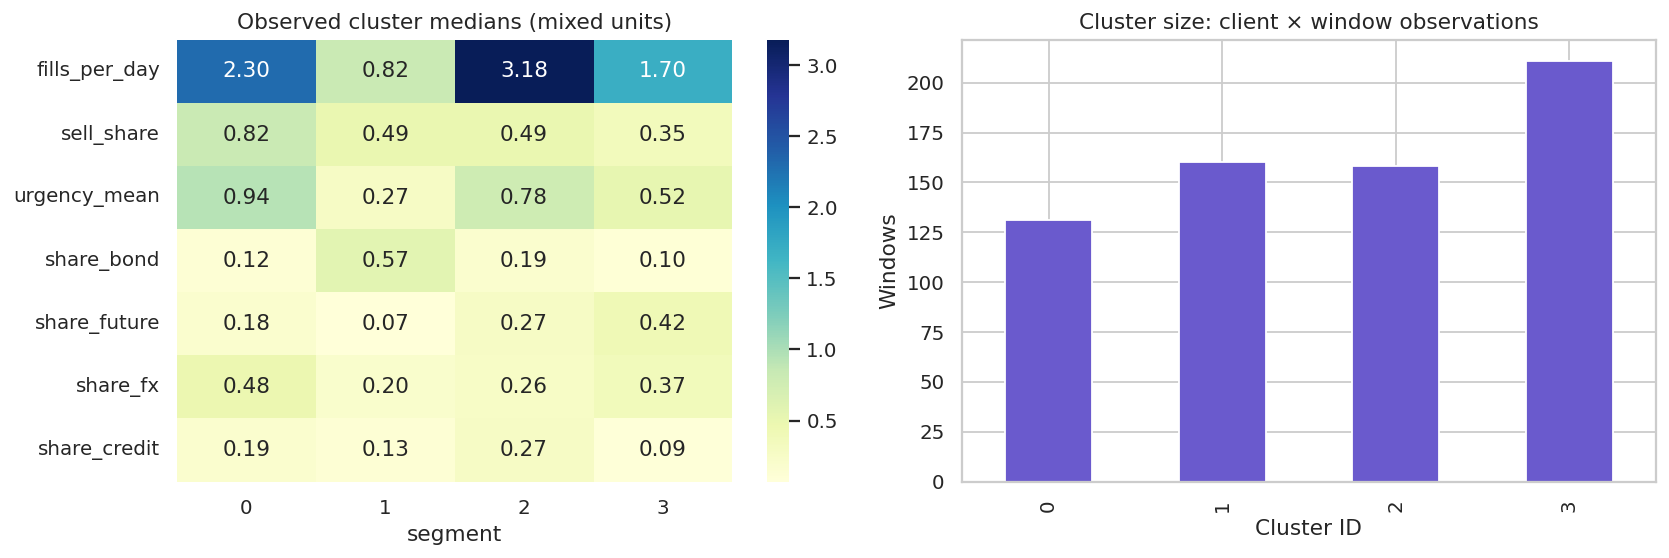

In [14]:
segment_profiles=(client_windows.loc[fit_mask].groupby('segment')[feature_cols]
                  .median().round(2))
display(segment_profiles.T)

profile_plot=segment_profiles[['fills_per_day','sell_share','urgency_mean',
                               'share_bond','share_future','share_fx','share_credit']]
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
sns.heatmap(profile_plot.T,cmap='YlGnBu',annot=True,fmt='.2f',ax=axs[0])
axs[0].set_title('Observed cluster medians (mixed units)')
segment_sizes=client_windows.loc[fit_mask].groupby('segment').size()
segment_sizes.plot(kind='bar',ax=axs[1],color='slateblue',title='Cluster size: client × window observations')
axs[1].set(xlabel='Cluster ID',ylabel='Windows');plt.tight_layout();plt.show()

### Synthetic validation (truth is for evaluation only)

After fitting unsupervised clusters, compare them with the simulated latent states. We attach the modal hidden state for each 20-day window. This **does not feed into K-means**.

Use Adjusted Rand Index (ARI) to compare two partitions without caring which integer ID each uses. A low ARI need not mean useless segments: real clients can have overlapping, mixed styles and the simulation label is only a generator setting.

Adjusted Rand Index train=0.875 | holdout=0.880


true_state,Defensive/deleveraging,Income hedger,Liquidity taker,Macro directional
segment,,,,
0,0.89,0.05,0.02,0.05
1,0.00,1.00,0.00,0.00
2,0.02,0.04,0.94,0.00
3,0.00,0.03,0.01,0.96


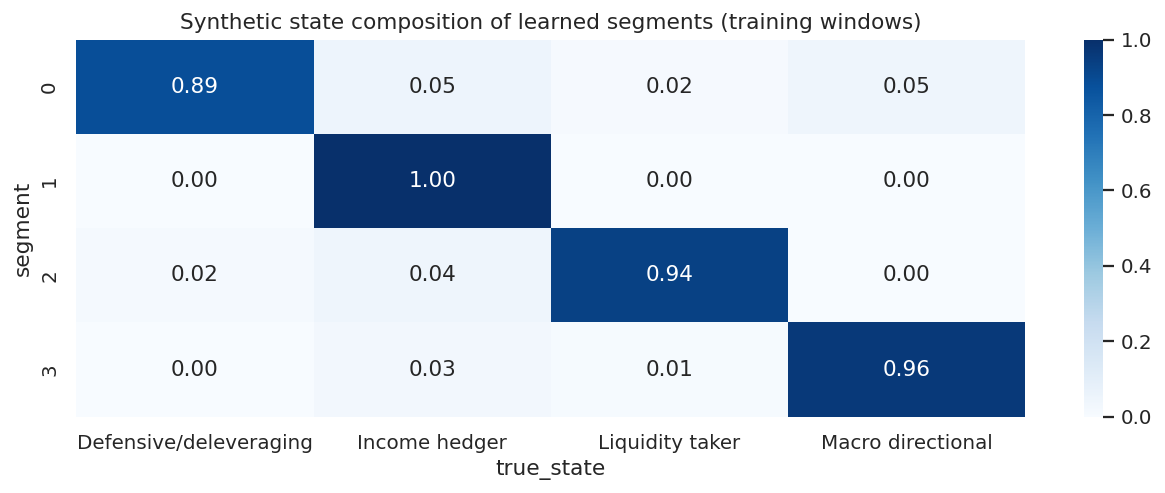

In [15]:
state_by_window=[]
for c,cid in enumerate(client_ids):
    for w in range(int(np.ceil(n_days/20))):
        first=w*20; last=min((w+1)*20,n_days)
        block=state[c,first:last]
        vals,counts=np.unique(block,return_counts=True)
        state_by_window.append((cid,w,str(vals[counts.argmax()])))
latent_summary=pd.DataFrame(state_by_window,columns=['client_id','window_id','true_state'])
client_windows=client_windows.merge(latent_summary,on=keys,validate='one_to_one')
true_num=client_windows.true_state.map(state_number)
ari_fit=adjusted_rand_score(true_num[fit_mask],client_windows.loc[fit_mask,'segment'])
ari_holdout=adjusted_rand_score(true_num[~fit_mask],client_windows.loc[~fit_mask,'segment'])
print(f'Adjusted Rand Index train={ari_fit:.3f} | holdout={ari_holdout:.3f}')
ct=pd.crosstab(client_windows.loc[fit_mask,'segment'],
               client_windows.loc[fit_mask,'true_state'],normalize='index')
display(ct.round(2))
fig,ax=plt.subplots(figsize=(10,4))
sns.heatmap(ct,cmap='Blues',annot=True,fmt='.2f',ax=ax)
ax.set_title('Synthetic state composition of learned segments (training windows)')
plt.tight_layout();plt.show()

### Exercise B (15 min): robust clustering

- Why does an unscaled `$20m` mean ticket dominate a 0–1 product share in Euclidean distance?
- Try `StandardScaler` versus `RobustScaler` and recompute the silhouette score.
- What changes if you include `market_stress` in the features? Are you grouping client styles, market conditions, or both?
- Can you justify using `k=4` if `k=3` scores higher? Explain the interpretability–granularity trade-off.

In [16]:
# EXERCISE B — experiment with scaling and silhouette. Avoid fitting on holdout windows.

## 6 — Dynamic segments: follow clients between groups

A one-off snapshot misses **movement**. For each client, we sort windows chronologically and compare consecutive cluster assignments. Because clustering can be noisy, report both:

- **Raw transitions:** every change in assigned group.
- **Persistent transitions:** a new group assigned for at least two consecutive windows, following at least one prior window in another group.

Even persistence does not establish a genuine behavioural regime change; use feature explanations, risk controls and analyst review.

Raw transitions: 159 | persistent new-segment starts: 136


segment,0,1,2,3
previous_segment,,,,
0,0.741,0.071,0.082,0.106
1,0.058,0.858,0.035,0.049
2,0.072,0.045,0.842,0.041
3,0.082,0.053,0.035,0.830


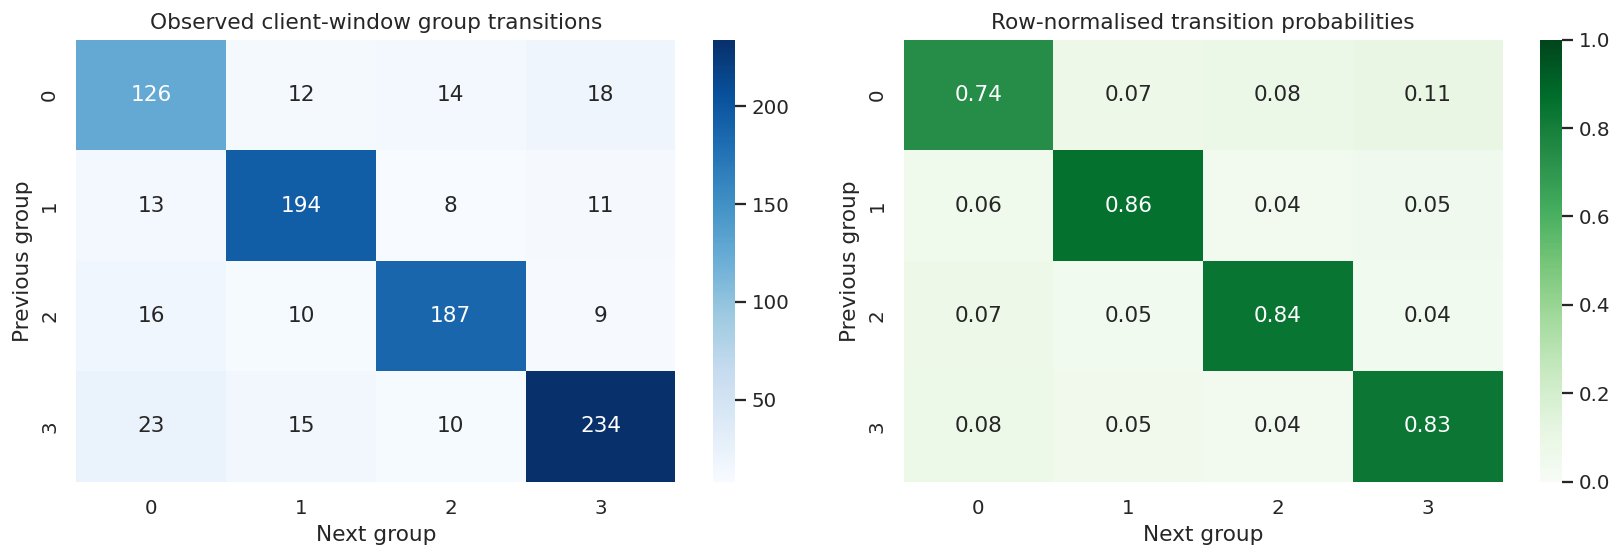

In [17]:
client_windows=client_windows.sort_values(['client_id','window_id']).reset_index(drop=True)
client_windows['previous_segment']=client_windows.groupby('client_id').segment.shift(1)
client_windows['raw_migration']=(client_windows.previous_segment.notna() &
                                 (client_windows.segment!=client_windows.previous_segment))
client_windows['next_segment']=client_windows.groupby('client_id').segment.shift(-1)
client_windows['persistent_migration']=(client_windows.raw_migration &
                                        (client_windows.next_segment==client_windows.segment))
print('Raw transitions:',int(client_windows.raw_migration.sum()),
      '| persistent new-segment starts:',int(client_windows.persistent_migration.sum()))

transitions=(client_windows.loc[client_windows.previous_segment.notna()]
             .groupby(['previous_segment','segment']).size().unstack(fill_value=0)
             .reindex(index=range(K),columns=range(K),fill_value=0))
transition_prob=transitions.div(transitions.sum(axis=1),axis=0)
display(transition_prob.round(3))
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
sns.heatmap(transitions,annot=True,fmt='d',cmap='Blues',ax=axs[0])
axs[0].set(title='Observed client-window group transitions',xlabel='Next group',ylabel='Previous group')
sns.heatmap(transition_prob,annot=True,fmt='.2f',cmap='Greens',vmin=0,vmax=1,ax=axs[1])
axs[1].set(title='Row-normalised transition probabilities',xlabel='Next group',ylabel='Previous group')
plt.tight_layout();plt.show()

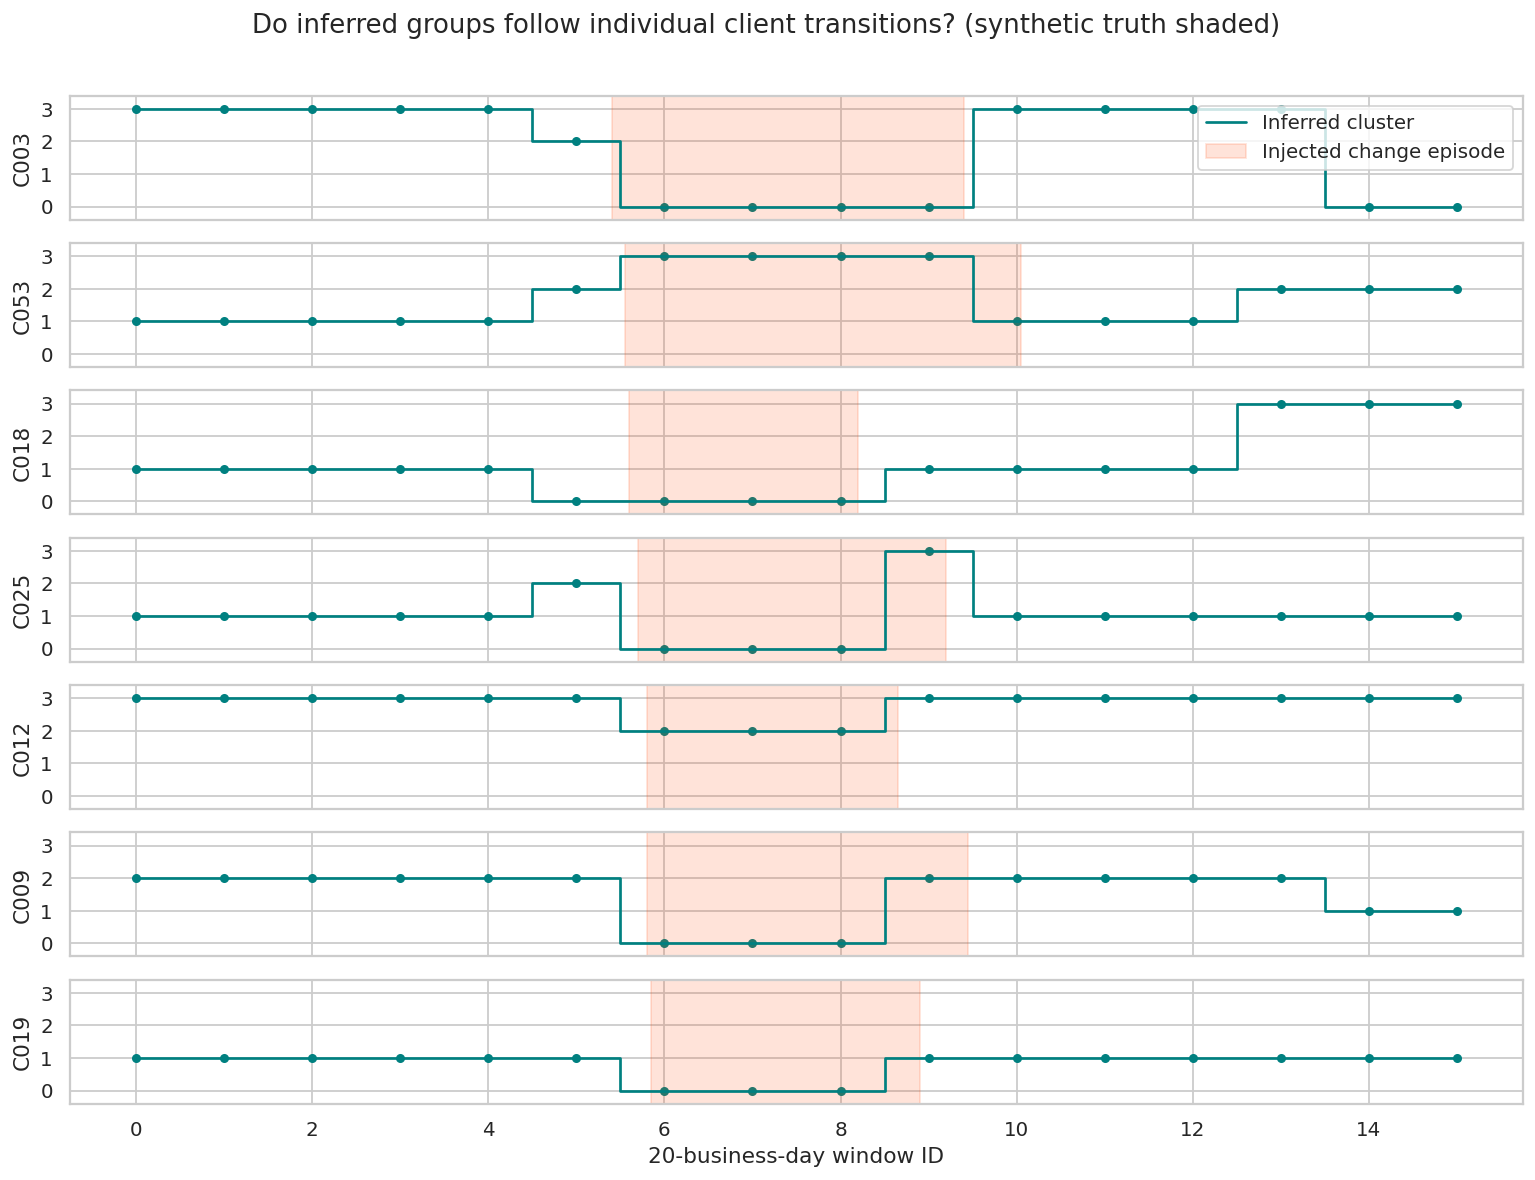

In [18]:
# Show inferred trajectories for several clients who *really* changed.
interesting_ids=(events.loc[events.kind=='temporary'].sort_values('start_day')
                 .client_id.head(7).tolist())
fig,axs=plt.subplots(len(interesting_ids),1,figsize=(12,9),sharex=True)
for i,cid in enumerate(interesting_ids):
    part=client_windows[client_windows.client_id==cid].sort_values('window_id')
    axs[i].step(part.window_id,part.segment,where='mid',label='Inferred cluster',color='teal')
    axs[i].scatter(part.window_id,part.segment,s=16,color='teal')
    known=events[(events.client_id==cid)&(events.kind=='temporary')].iloc[0]
    axs[i].axvspan(known.start_day/20,known.end_day/20,alpha=.15,color='orangered',label='Injected change episode')
    axs[i].set(ylabel=cid,yticks=range(K),ylim=(-.4,K-.6))
axs[0].legend(loc='upper right')
axs[-1].set_xlabel('20-business-day window ID')
fig.suptitle('Do inferred groups follow individual client transitions? (synthetic truth shaded)',y=1.01)
plt.tight_layout();plt.show()

### Exercise C (15 min): construct a migration matrix from scratch

Given `[S0, S0, S1, S1, S2, S0]`, count five transitions, including self-transitions. Build a 4×4 matrix and row-normalise it. Then consider **dwell time**: which clients genuinely changed style, versus flipping labels for one noisy window?

In [19]:
# EXERCISE C — implement transition_counts(labels, k) using pure Python or NumPy.
toy_sequence=[0,0,1,1,2,0]

## 7 — Change detection beyond K-means

Client group changes and feature distribution changes are not identical.

**Method 1: Jensen–Shannon distance** compares a client's recent asset-class mix with its own earlier mix. It is symmetric and bounded in `[0,1]` with base-2 log; 0 = identical mixes. This is useful for product preference migration.

\(JS(P,Q)=\sqrt{\tfrac12 KL(P||M)+\tfrac12 KL(Q||M)},\quad M=(P+Q)/2\)

**Method 2: multivariate shift score** compares today's normalised behaviour vector with that client's past three windows; a training-period threshold determines alerts.

**Method 3: one-sided CUSUM** accumulates small, persistent changes in an individual metric rather than reacting to a single outlier.

We will contrast changes in *raw slippage* against changes **relative to other clients**. During market stress, raw costs typically rise across everyone; client-specific deviations are more informative.

In [20]:
share_cols=[f'share_{a.lower()}' for a in ASSETS]
def js_distance(p:np.ndarray,q:np.ndarray)->float:
    '''Jensen–Shannon distance; robust to zero observed product shares.'''
    p=np.asarray(p,dtype=float);q=np.asarray(q,dtype=float)
    if p.shape!=q.shape or p.ndim!=1 or len(p)==0 or (p<0).any() or (q<0).any():
        raise ValueError('expected same-sized nonnegative vectors')
    if p.sum()<=0 or q.sum()<=0: raise ValueError('empty probability vector')
    return float(jensenshannon(p/p.sum(),q/q.sum(),base=2))

assert abs(js_distance(np.array([1,0]),np.array([1,0])))<1e-12
assert abs(js_distance(np.array([1,0]),np.array([0,1]))-1.0)<1e-12

# Client windows are sorted. Compare each product mix with average of preceding three.
for col in share_cols:
    client_windows[f'past_{col}']=(client_windows.groupby('client_id')[col]
                      .transform(lambda x:x.shift(1).rolling(3,min_periods=2).mean()))

client_windows['js_product_shift']=client_windows.apply(
    lambda row:js_distance(row[share_cols].to_numpy(dtype=float),
                           row[[f'past_{x}' for x in share_cols]].to_numpy(dtype=float))
    if pd.notna(row[f'past_{share_cols[0]}']) else np.nan,axis=1)

# Peer-adjusted slippage excludes shared market-level deterioration.
client_windows['peer_median_cost']=(client_windows.groupby('window_id')
                                    .weighted_cost_bps.transform('median'))
client_windows['relative_cost_bps']=client_windows.weighted_cost_bps-client_windows.peer_median_cost
display(client_windows[['client_id','window_id','js_product_shift','weighted_cost_bps',
                        'peer_median_cost','relative_cost_bps']].dropna().head(5))

,client_id,window_id,js_product_shift,weighted_cost_bps,peer_median_cost,relative_cost_bps
2,C001,2,0.024589,8.243172,6.688127,1.555045
3,C001,3,0.074230,7.757244,6.530861,1.226384
4,C001,4,0.139012,7.273999,6.762187,0.511812
5,C001,5,0.043688,12.815477,11.214518,1.600959
6,C001,6,0.249395,14.756538,14.115535,0.641003


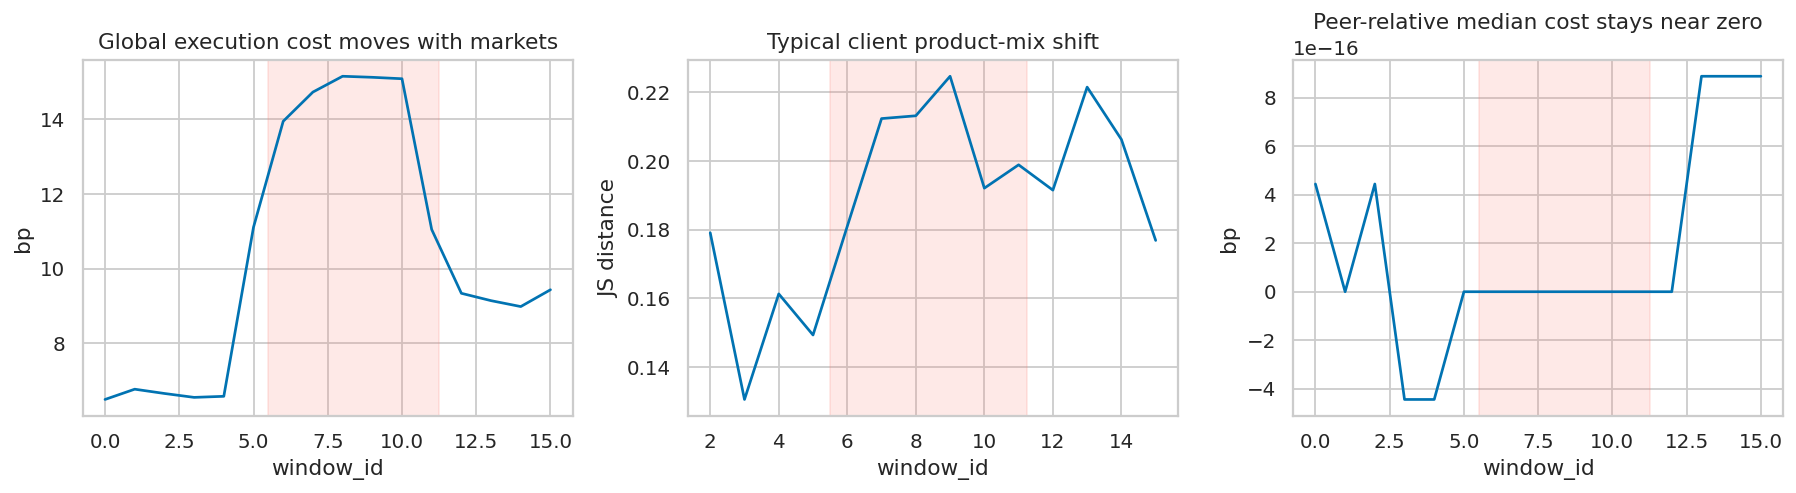

In [21]:
fig,axs=plt.subplots(1,3,figsize=(14,4))
global_by_window=client_windows.groupby('window_id').agg(
    mean_cost=('weighted_cost_bps','mean'),
    median_js=('js_product_shift','median'),
    median_relative_cost=('relative_cost_bps','median'))
global_by_window.mean_cost.plot(ax=axs[0],title='Global execution cost moves with markets')
global_by_window.median_js.plot(ax=axs[1],title='Typical client product-mix shift')
global_by_window.median_relative_cost.plot(ax=axs[2],title='Peer-relative median cost stays near zero')
for a in axs: a.axvspan(110/20,225/20,color='salmon',alpha=.17)
axs[0].set_ylabel('bp');axs[1].set_ylabel('JS distance');axs[2].set_ylabel('bp')
plt.tight_layout();plt.show()

### Change score with a historical-only baseline

Use a small, interpretable set of features for detecting changes. We use the **same scaler fit on training windows**, then compare each client to its own **preceding** three windows. The threshold is defined by the training distribution (`window_id <= 10`), then applied unchanged to holdout windows.

The score is a monitoring heuristic. In production, calibrate with actual operational review cost, validate drift by segment and avoid overlapping label leakage.

In [22]:
detector_cols=['fills_per_day','sell_share','urgency_mean','share_bond',
               'share_future','share_fx','share_credit','relative_cost_bps']
detector_scaler=RobustScaler(quantile_range=(10,90))
detector_scaler.fit(client_windows.loc[fit_mask,detector_cols])
scaled=detector_scaler.transform(client_windows[detector_cols])
for j,col in enumerate(detector_cols):
    client_windows[f'z_{col}']=scaled[:,j]

def previous_three_mean(s:pd.Series)->pd.Series:
    return s.shift(1).rolling(3,min_periods=2).mean()

for col in detector_cols:
    client_windows[f'baseline_{col}']=(client_windows.groupby('client_id')[col]
                                        .transform(previous_three_mean))
    client_windows[f'baseline_z_{col}']=(client_windows.groupby('client_id')[f'z_{col}']
                                           .transform(previous_three_mean))
    client_windows[f'delta_{col}']=client_windows[f'z_{col}']-client_windows[f'baseline_z_{col}']

delta_cols=[f'delta_{c}' for c in detector_cols]
client_windows['change_score']=np.sqrt((client_windows[delta_cols]**2).sum(axis=1,min_count=len(delta_cols)))
train_scores=client_windows.loc[fit_mask,'change_score'].dropna()
shift_threshold=float(train_scores.quantile(.90))
client_windows['change_alert']=client_windows.change_score>shift_threshold
print('Frozen 90th-percentile TRAINING score threshold:',round(shift_threshold,3))
print('Training alert rate:',round(client_windows.loc[fit_mask,'change_alert'].mean(),3),
      'Holdout alert rate:',round(client_windows.loc[~fit_mask,'change_alert'].mean(),3))

Frozen 90th-percentile TRAINING score threshold: 1.386
Training alert rate: 0.082 Holdout alert rate: 0.18


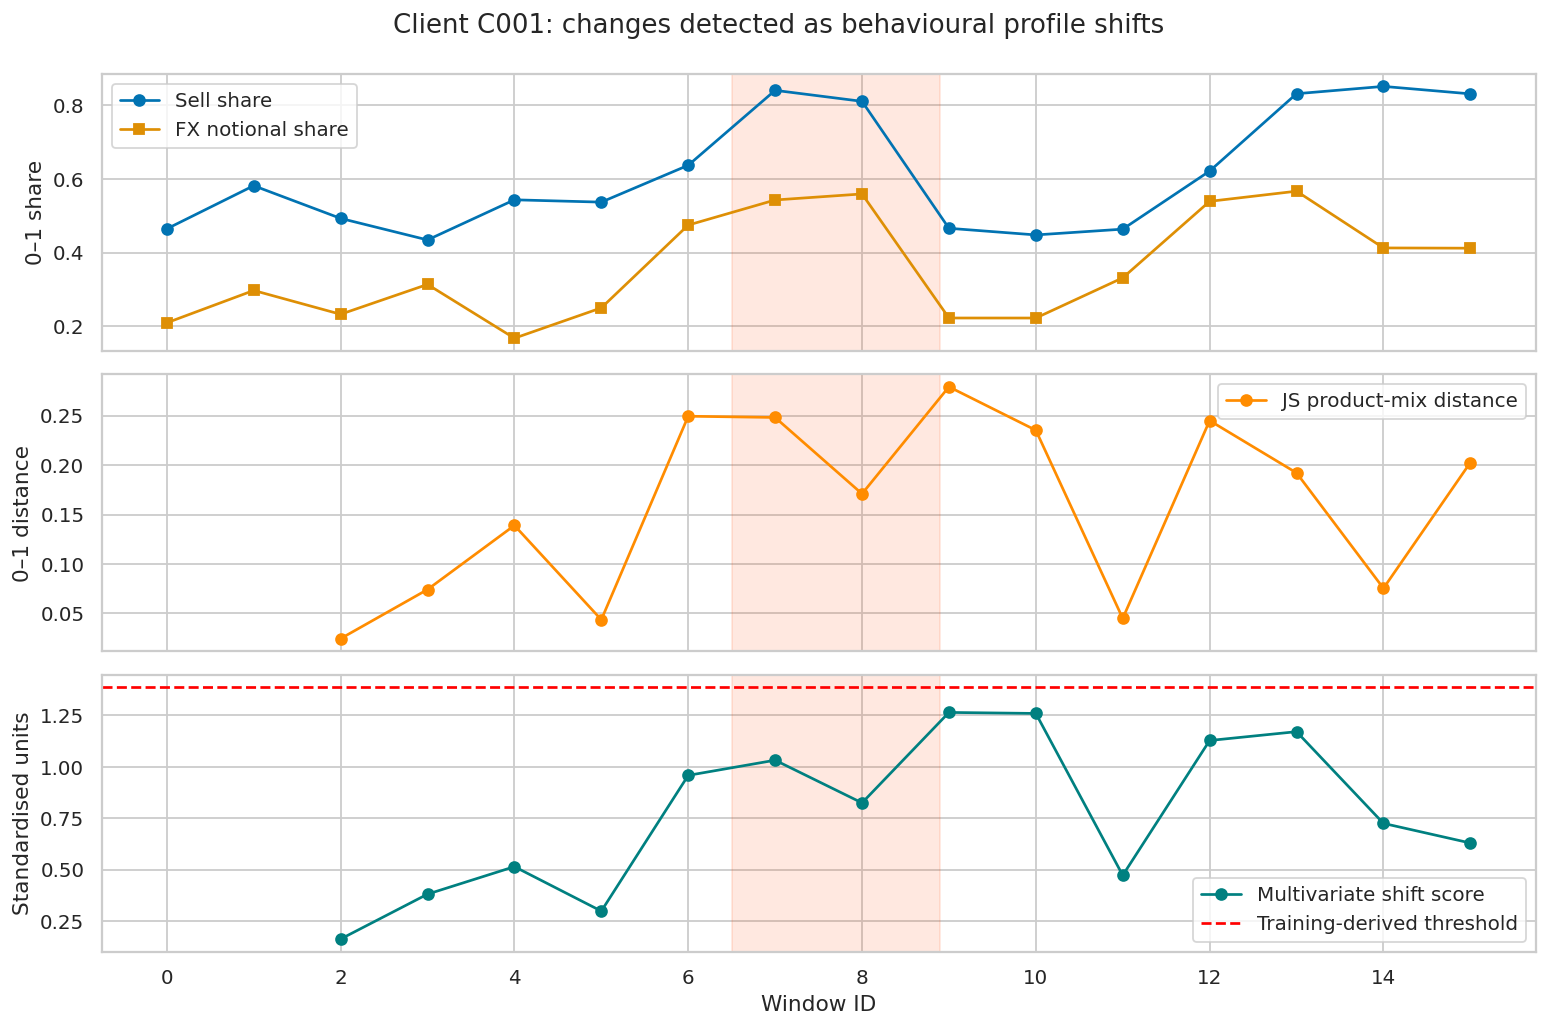

In [23]:
# Individual client example with known injected change date (truth only for shading).
focus=str(events.loc[events.to_state=='Defensive/deleveraging','client_id'].iloc[0])
series=client_windows.loc[client_windows.client_id==focus].sort_values('window_id')
known=events.loc[events.client_id==focus].iloc[0]
fig,axs=plt.subplots(3,1,figsize=(12,8),sharex=True)
axs[0].plot(series.window_id,series.sell_share,'o-',label='Sell share')
axs[0].plot(series.window_id,series.share_fx,'s-',label='FX notional share')
axs[0].legend();axs[0].set_ylabel('0–1 share')
axs[1].plot(series.window_id,series.js_product_shift,'o-',color='darkorange',label='JS product-mix distance')
axs[1].legend();axs[1].set_ylabel('0–1 distance')
axs[2].plot(series.window_id,series.change_score,'o-',color='teal',label='Multivariate shift score')
axs[2].axhline(shift_threshold,color='red',ls='--',label='Training-derived threshold')
axs[2].scatter(series.loc[series.change_alert,'window_id'],
               series.loc[series.change_alert,'change_score'],color='red',zorder=4)
axs[2].legend();axs[2].set_ylabel('Standardised units');axs[2].set_xlabel('Window ID')
for a in axs: a.axvspan(known.start_day/20,known.end_day/20,color='orangered',alpha=.12)
fig.suptitle(f'Client {focus}: changes detected as behavioural profile shifts',y=.99)
plt.tight_layout();plt.show()

### CUSUM: a lightweight change-point detector

For a standardised signal `z_t`, an upper CUSUM can be written as `S_t = max(0, S_(t−1) + z_t − k)`. Alarm if `S_t > h`, then reset. Lower CUSUM uses `−z_t`. The allowance `k` tolerates ordinary fluctuations and `h` trades sensitivity against false alarms. **Use only past observations to estimate the baseline**; re-baselining after confirmed changes is an operational policy.

We implement the detector ourselves as live-coding practice.

Client C001: 32 CUSUM alerts (including noise-related false alarms)


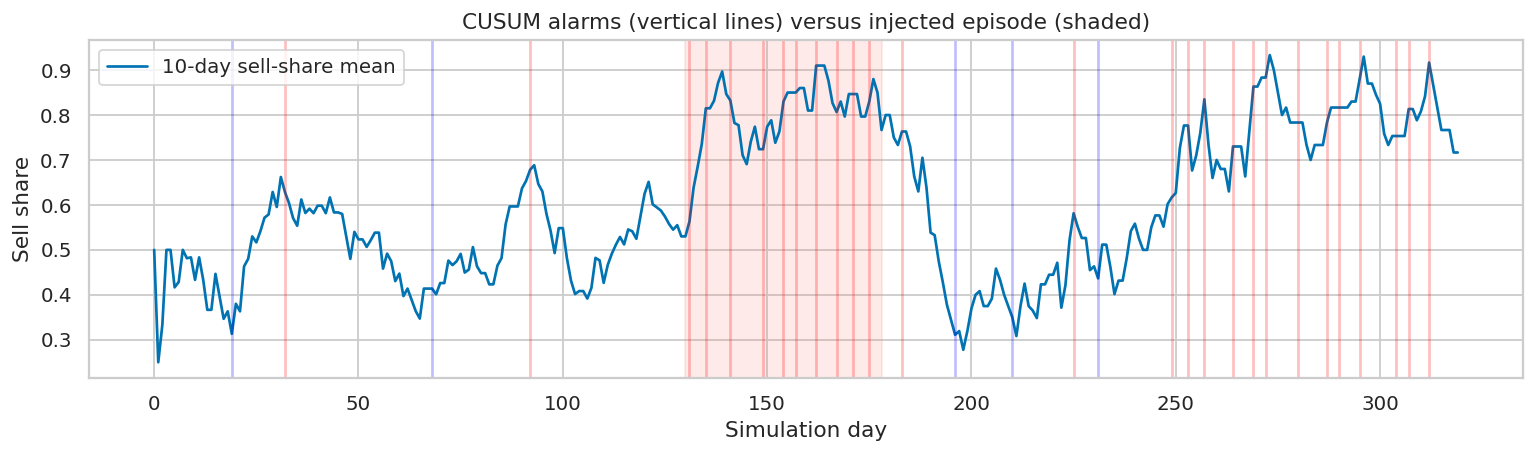

In [24]:
def cusum_two_sided(values,baseline_mean,baseline_std,k=.35,h=3.0):
    '''Causal two-sided CUSUM; return event index and direction.'''
    if baseline_std<=0 or h<=0: raise ValueError('invalid baseline or threshold')
    positive=negative=0.0
    alerts=[]
    for i,x in enumerate(values):
        z=(float(x)-baseline_mean)/baseline_std
        positive=max(0.0,positive+z-k)
        negative=max(0.0,negative-z-k)
        if positive>h:
            alerts.append((i,'up'))
            positive=0.0
        if negative>h:
            alerts.append((i,'down'))
            negative=0.0
    return alerts

# Illustration: client selling share shifts for a time, then returns.
focus_day=trades.loc[trades.client_id==focus].groupby('day_idx').sell_indicator.mean()
client_daily_sell=focus_day.reindex(np.arange(n_days)).fillna(0.5)
mu=float(client_daily_sell.iloc[:90].mean())
sd=max(float(client_daily_sell.iloc[:90].std()),.10)
cusum_alerts=cusum_two_sided(client_daily_sell.to_numpy(),mu,sd,k=.15,h=4.5)
print(f'Client {focus}:',len(cusum_alerts),'CUSUM alerts (including noise-related false alarms)')
fig,ax=plt.subplots(figsize=(12,3.7))
client_daily_sell.rolling(10,min_periods=1).mean().plot(ax=ax,label='10-day sell-share mean')
for i,direction in cusum_alerts: ax.axvline(i,alpha=.25,color='red' if direction=='up' else 'blue')
ax.axvspan(known.start_day,known.end_day,color='salmon',alpha=.16)
ax.set(xlabel='Simulation day',ylabel='Sell share',title='CUSUM alarms (vertical lines) versus injected episode (shaded)')
ax.legend();plt.tight_layout();plt.show()

### Exercise D (15 min): design a change detector

Implement a **one-sided** CUSUM detector from scratch. Test against a constant sequence (no alarms) and a sequence with a +2 standard-deviation shift starting at step 40. Discuss why CUSUM can detect gradual drift earlier than a simple one-day threshold.

### Exercise E (15 min): peer normalisation

Recalculate cost alerts two ways: raw slippage and `client_slippage − peer_median_slippage` for each window. Which signals fire together during risk-off? What would you do if most peers are also changing their client strategy?

In [25]:
# EXERCISES D/E — your implementation.

## 8 — Evaluate detections against injected transitions

We know the hidden synthetic change dates, so we can test alerts. Here we use a transparent, event-level notion of recall: a temporary transition is “caught” when a client shift alert occurs within **one 20-day bucket** of the transition bucket. A complete real evaluation also measures false-alarm events per client-month, detection delay, review workload and performance by market regime.

**Caution:** A single noisy episode can generate several alerts. Trade-level precision, window-level precision and event-level precision are different denominators—never mix them.

In [26]:
event_starts=events[['client_id','start_day','to_state','kind']].copy()
event_starts['transition_window']=(event_starts.start_day//20).astype(int)

def event_recall(event_table,detected_windows,tolerance=1):
    caught=[]
    for event in event_table.itertuples(index=False):
        c=detected_windows.get(event.client_id,[])
        caught.append(any(abs(w-event.transition_window)<=tolerance for w in c))
    return float(np.mean(caught)),caught

detected=(client_windows.loc[client_windows.change_alert]
          .groupby('client_id').window_id.apply(list).to_dict())
persisted=(client_windows.loc[client_windows.persistent_migration]
           .groupby('client_id').window_id.apply(list).to_dict())
change_recall,caught_change=event_recall(event_starts,detected,1)
cluster_recall,caught_cluster=event_recall(event_starts,persisted,1)
print(f'Event recall (multivariate score, ±1 bucket): {change_recall:.1%}')
print(f'Event recall (persistent cluster migration, ±1 bucket): {cluster_recall:.1%}')
print('These are detection *recalls*, not precisions.')

event_starts['score_caught']=caught_change
event_starts['cluster_caught']=caught_cluster
display(event_starts.groupby('to_state')[['score_caught','cluster_caught']].mean().round(2))

Event recall (multivariate score, ±1 bucket): 55.4%
Event recall (persistent cluster migration, ±1 bucket): 96.4%
These are detection *recalls*, not precisions.


,score_caught,cluster_caught
to_state,,
Defensive/deleveraging,0.48,1.00
Income hedger,0.71,0.79
Liquidity taker,0.80,1.00
Macro directional,0.43,1.00


,windows,alert_rate,migration_rate,mean_cost
window_market_regime,,,,
Calm,360,0.008,0.025,7.365
Recovery,300,0.180,0.220,9.592
Risk-off,300,0.170,0.280,14.804


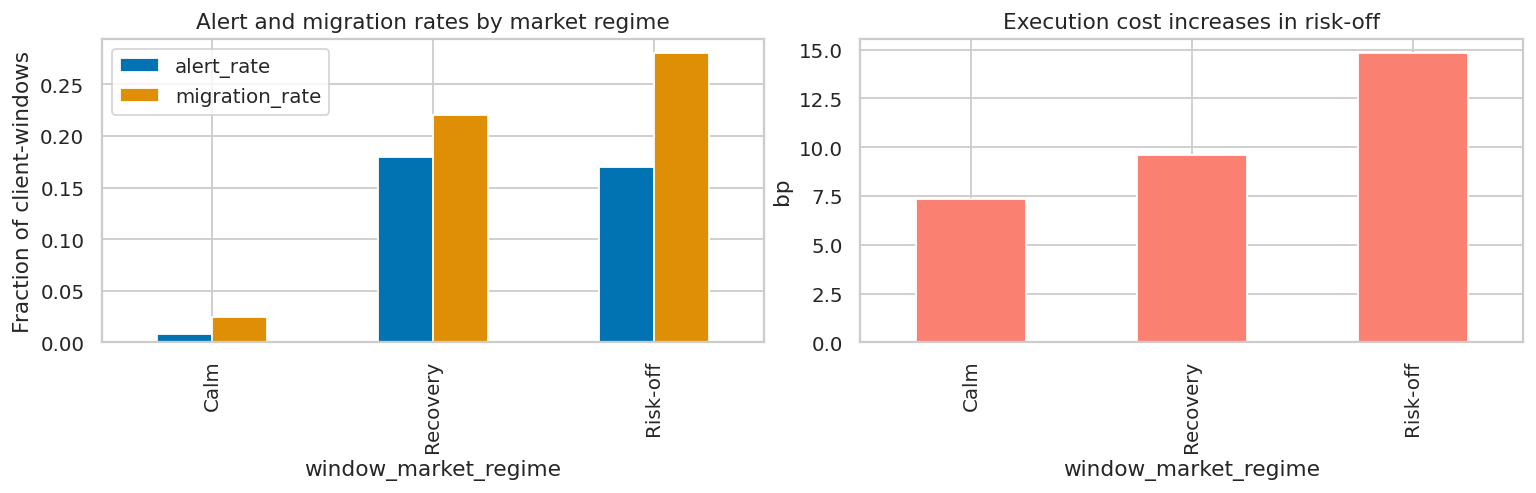

In [27]:
# Regime stratification: broad market stress can affect rates of client alerts.
regime_monitor=(client_windows.groupby('window_market_regime').agg(
      windows=('client_id','count'),
      alert_rate=('change_alert','mean'),
      migration_rate=('raw_migration','mean'),
      mean_cost=('weighted_cost_bps','mean')).round(3))
display(regime_monitor)
fig,axs=plt.subplots(1,2,figsize=(12,4))
regime_monitor[['alert_rate','migration_rate']].plot(kind='bar',ax=axs[0],title='Alert and migration rates by market regime')
regime_monitor['mean_cost'].plot(kind='bar',ax=axs[1],color='salmon',title='Execution cost increases in risk-off')
axs[0].set_ylabel('Fraction of client-windows');axs[1].set_ylabel('bp')
plt.tight_layout();plt.show()

### Event study: test a client's pre/post change

Choose one injected event **for demonstration only**. Compare client sell share in the three windows before versus three windows after, with bootstrap uncertainty. This is not a causal analysis because market conditions and other client activity also change; real attribution would require an appropriate control group and market adjustments.

Client C001, sell-share change post minus pre: +0.200
Naive bootstrap 95% CI [-0.037, +0.361] (tiny samples, not causal)


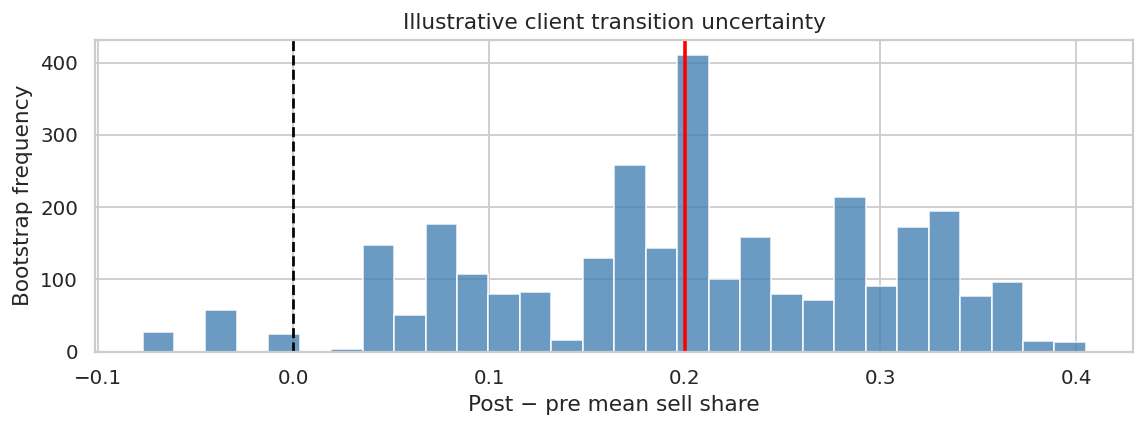

In [28]:
focus_event=events.loc[events.to_state=='Defensive/deleveraging'].iloc[0]
eclient=focus_event.client_id
w0=int(focus_event.start_day//20)
course=client_windows.loc[client_windows.client_id==eclient].set_index('window_id')
pre=course.loc[(course.index>=w0-3)&(course.index<w0),'sell_share'].to_numpy()
post=course.loc[(course.index>=w0+1)&(course.index<=w0+3),'sell_share'].to_numpy()
if len(pre)>=2 and len(post)>=2:
    observed=post.mean()-pre.mean()
    boot=np.array([rng.choice(post,len(post),replace=True).mean()-
                   rng.choice(pre,len(pre),replace=True).mean() for _ in range(3000)])
    lo,hi=np.quantile(boot,[.025,.975])
    print(f'Client {eclient}, sell-share change post minus pre: {observed:+.3f}')
    print(f'Naive bootstrap 95% CI [{lo:+.3f}, {hi:+.3f}] (tiny samples, not causal)')
    fig,ax=plt.subplots(figsize=(9,3.5))
    ax.hist(boot,bins=30,color='steelblue',alpha=.8)
    ax.axvline(0,color='black',ls='--');ax.axvline(observed,color='red',lw=2)
    ax.set(xlabel='Post − pre mean sell share',ylabel='Bootstrap frequency',title='Illustrative client transition uncertainty')
    plt.tight_layout();plt.show()

## 9 — Client drift explanation and production design

### What changed for this client?

A user-facing analyst view should name **observed differences**, the context and exact lookback periods—not assert an unobserved motive (e.g., “client is in financial distress”). Build a simple explanation from deltas in comparable features.

In [29]:
def explain_change(cid:str,window_id:int,top_n:int=5)->pd.DataFrame:
    row=client_windows.loc[(client_windows.client_id==cid)&(client_windows.window_id==window_id)]
    if len(row)!=1: raise KeyError('unknown client-window')
    row=row.iloc[0]
    out=pd.DataFrame([{
        'feature':f,'current':row[f],
        'prior_3window_mean':row[f'baseline_{f}'],
        'standardised_delta':row[f'delta_{f}']}
        for f in detector_cols])
    out['absolute_shift']=out.standardised_delta.abs()
    return out.sort_values('absolute_shift',ascending=False).head(top_n)

recent_alerts=client_windows.loc[client_windows.change_alert].sort_values('change_score',ascending=False)
if len(recent_alerts):
    sample_alert=recent_alerts.iloc[0]
    print('Explanation for alert:',sample_alert.client_id,'window',sample_alert.window_id)
    display(explain_change(sample_alert.client_id,int(sample_alert.window_id)).round(3))

Explanation for alert: C057 window 7


,feature,current,prior_3window_mean,standardised_delta,absolute_shift
5,share_fx,0.680,0.097,1.748,1.748
3,share_bond,0.052,0.686,-1.175,1.175
1,sell_share,0.850,0.317,1.027,1.027
2,urgency_mean,0.959,0.264,1.011,1.011
7,relative_cost_bps,0.794,-2.623,0.864,0.864


### Whiteboard architecture

```mermaid
flowchart TD
    A[Trade events] --> B[Validation and event-time deduplication]
    C[Client reference and entitlements] --> D[Client feature store]
    B --> D
    E[Market stress and regimes] --> D
    D --> F[Segment assignment]
    D --> G[Change scores and CUSUM]
    F --> H[Migration and explanation]
    G --> H
    H --> I[Analyst review and outcomes]
    I --> J[Monitoring and model governance]
```

### Important implementation decisions

| Question | Senior-level answer |
|---|---|
| Late or amended fills? | Event time, ingestion time, retractions and idempotent keys; recompute affected features |
| As-of correctness? | Watermarks and window-end cutoffs; no future trades in a historical snapshot |
| Cluster stability? | Version scaler and centroids, monitor reassignment and validate drift before retraining |
| Arbitrary cluster IDs? | Preserve a versioned mapping between old/new centroid identities before discussing migration |
| Segment migration vs market shift? | Compare personal change, peers and external market regime before escalating |
| What if a client trades rarely? | Minimum trade-volume rule, wider windows, missingness and abstention |
| What if a new client arrives? | Cold-start from reference attributes, uncertainty badge, avoid forced confident classification |
| Privacy / entitlements? | Pseudonymous client IDs, least-privilege access, separation of client and public market data |
| What to monitor? | Transaction quality, per-segment stability, migration frequency, alert workload and review outcomes |
| How to deploy? | Batch feature jobs first; streaming only if operational use case justifies latency |

**Interview challenge:** If the client changes from high-frequency trading to low-frequency trading, does lower transaction count imply lost wallet share? No: look for changes in client holdings, product mix, seasonal effects, execution routing, parent-order size, mandates and external market volume.

### Exercise F (15 min): client transition explanation

Given two windows of the same client, return the top three features with the largest **standardised** difference. Explain why raw dollar change in turnover should not be directly compared with a change in a 0–1 product share.

### Exercise G (10 min): monitoring tests

Write tests that ensure there are no duplicate client-window keys, a product-share row sums to 1, no fit-time feature includes `true_state`, and all holdout windows were transformed by **training-fitted** scaler and cluster centroids.

In [30]:
# EXERCISES F/G — your own tests and change explanation.

## 10 — Worked Python solutions

Attempt the coding drills before executing these cells. In interviews, explain complexity, assumptions and edge cases, then write a small test.

In [31]:
# A: point-in-time rolling client features from fills
cutoff=pd.Timestamp('2025-10-01 16:00')
since=cutoff-pd.Timedelta(days=28)  # business-day windows need trading calendar in production
recent=trades.loc[(trades.timestamp<=cutoff)&(trades.timestamp>since)].copy()
recent['slippage_dollars']=recent.slippage_bps*recent.notional_usd
point_in_time=(recent.groupby('client_id').agg(
   turnover_usd=('notional_usd','sum'),
   weighted_slippage_num=('slippage_dollars','sum'),
   signed_notional=('signed_notional_usd','sum')))
point_in_time['weighted_slippage_bps']=point_in_time.weighted_slippage_num/point_in_time.turnover_usd
point_in_time['flow_imbalance']=point_in_time.signed_notional/point_in_time.turnover_usd
top_two=(recent.groupby(['client_id','instrument']).notional_usd.sum().reset_index()
         .sort_values('notional_usd',ascending=False).groupby('client_id').head(2))
assert (recent.timestamp<=cutoff).all() and top_two.groupby('client_id').size().max()<=2
display(point_in_time[['turnover_usd','weighted_slippage_bps','flow_imbalance']].head())

,turnover_usd,weighted_slippage_bps,flow_imbalance
client_id,,,
C001,2.073629e+08,10.139143,-0.078136
C002,2.650785e+08,9.966103,0.050414
C003,3.369906e+08,9.547287,-0.744364
C004,2.337412e+08,10.899145,0.300243
C005,4.528847e+08,11.708651,-0.651973


In [32]:
# B: scaling comparisons (without fitting to test windows)
from sklearn.preprocessing import StandardScaler
standard_x=StandardScaler().fit_transform(client_windows.loc[fit_mask,feature_cols])
score_standard=silhouette_score(standard_x,KMeans(n_clusters=4,n_init=15,random_state=SEED).fit_predict(standard_x))
score_robust=silhouette_score(X_fit,kmeans.labels_)
print(f'Four-cluster silhouette: StandardScaler={score_standard:.3f}, RobustScaler={score_robust:.3f}')

# C: compact transition counter, including self-transitions
def transition_counts(sequence,k:int)->np.ndarray:
    counts=np.zeros((k,k),dtype=int)
    for prev,nxt in zip(sequence[:-1],sequence[1:]):
        if not (0<=prev<k and 0<=nxt<k):raise ValueError('invalid state label')
        counts[prev,nxt]+=1
    return counts

toy=transition_counts([0,0,1,1,2,0],4)
print('Toy transition matrix:');display(pd.DataFrame(toy))
assert toy.sum()==5 and toy[0,0]==1 and toy[2,0]==1

Four-cluster silhouette: StandardScaler=0.363, RobustScaler=0.355
Toy transition matrix:


,0,1,2,3
0,1,1,0,0
1,0,1,1,0
2,1,0,0,0
3,0,0,0,0


In [33]:
# D: one-sided detector; test delayed sustained change
def upper_cusum(values,k=.5,h=6.):
    score=0.;alerts=[]
    for i,x in enumerate(values):
        score=max(0.,score+float(x)-k)
        if score>h:
            alerts.append(i)
            score=0.
    return alerts

assert upper_cusum(np.zeros(100))==[]
synthetic_jump=np.r_[np.zeros(40),np.ones(45)*2]
assert any(i>=40 for i in upper_cusum(synthetic_jump))
print('CUSUM first jump detection:',upper_cusum(synthetic_jump)[0])

# E: raw-versus-peer-adjusted cost alerts
example_cost=client_windows[['client_id','window_id','weighted_cost_bps','relative_cost_bps']].copy()
raw_cut=float(client_windows.loc[fit_mask,'weighted_cost_bps'].quantile(.90))
peer_cut=float(client_windows.loc[fit_mask,'relative_cost_bps'].quantile(.90))
example_cost['raw_alert']=example_cost.weighted_cost_bps>raw_cut
example_cost['peer_alert']=example_cost.relative_cost_bps>peer_cut
print('Raw cost alerts:',int(example_cost.raw_alert.sum()),
      '| peer-normalised alerts:',int(example_cost.peer_alert.sum()))

CUSUM first jump detection: 44
Raw cost alerts: 66 | peer-normalised alerts: 111


In [34]:
# F: rank differences in consistent standardised units
def top_feature_changes(cid:str,w1:int,w2:int,n=3)->pd.Series:
    a=client_windows[(client_windows.client_id==cid)&(client_windows.window_id==w1)]
    b=client_windows[(client_windows.client_id==cid)&(client_windows.window_id==w2)]
    if len(a)!=1 or len(b)!=1:raise KeyError('unknown client window')
    fields=[f'z_{c}' for c in detector_cols]
    changes=(b.iloc[0][fields].astype(float)-a.iloc[0][fields].astype(float)).abs()
    changes.index=detector_cols
    return changes.nlargest(n)
display(top_feature_changes(client_ids[0],4,9))

# G: data/temporal invariants and absence of synthetic truth in model feature list
assert client_windows[['client_id','window_id']].duplicated().sum()==0
assert np.allclose(client_windows[share_cols].sum(axis=1),1)
assert 'true_state' not in feature_cols and 'true_client_state' not in feature_cols
assert (client_windows.loc[~fit_mask,'window_id']>client_windows.loc[fit_mask,'window_id'].max()).all()
assert len(kmeans.cluster_centers_)==K
print('Data quality, no-leakage and holdout invariants passed.')

Data quality, no-leakage and holdout invariants passed.


relative_cost_bps    0.319836
share_fx             0.164176
sell_share           0.148501
dtype: float64

## 11 — Mock senior interview (35 minutes)

**Prompt:** “We want to group our institutional clients based on their trading behaviour. Over the last three months several large clients changed product mix, sold more bonds, and had higher execution costs. Build something that tells us who changed, why, and what to investigate.”

### 0–5 min: define the outcome

Are we identifying sales opportunities, retention risk, suitability reviews, liquidity planning, adverse execution, or fraud indicators? Each needs different labels, tolerance for false positives and human review.

### 5–12 min: design features

Use point-in-time client × 20-day features: activity, notional, product mix, flow imbalance, urgency, execution quality, concentration. Separate stable client descriptors from behaviour. Version data and use explicit windows.

### 12–20 min: cluster and explain

Fit scaler and K-means on historical training windows; compare `k`, inspect silhouette and group medians. Cluster assignments are not facts: label them with analyst input, measure stability and annotate confidence/abstention.

### 20–27 min: follow changes

Detect moves across groups, confirm persistence, compare recent distributions with each client's historical baseline, run CUSUM and peer-relative cost analysis. Account for common market risk-off periods before claiming client-specific shifts.

### 27–35 min: controls and scale

Discuss late trade corrections, immutable events, client entitlements, data quality, feature snapshots, latency, business review outcomes, threshold economics, drift, audit trail, governance and retraining controls.

### Strong closing answer

> “I would build a time-aware client behaviour representation from transactions, including activity, product mix, trade direction, order size and execution quality. I would discover groups using a transparent baseline such as scaled K-means, but track each client's evolution over time rather than treating the assignment as permanent. I would distinguish market-wide regime changes from individual client changes using peer comparisons, persistence and change-point detection. Every alert would show what changed, over which period, and what data supports it, with an analyst able to review, dismiss or escalate it.”

### Stretch tasks for a second practice session

1. Implement a **Markov transition model** for behaviour-state persistence, using observed segment sequences rather than synthetic state labels.
2. Replace hard K-means labels with **soft Gaussian mixture probabilities**, and alert only when a transition exceeds a confidence threshold.
3. Build a streaming feature updater with event-time watermarks and late-fill corrections.
4. Add change-point evaluation under varied shift magnitudes, event durations and missing trades.
5. Separate the effects of market stress and client style via a hierarchical/regression model with client random effects.

**Boundary:** This is simulated educational data. Grouping a client by transactions is useful for review and analysis; it does not reveal a client's intent or establish financial distress, fraud or suitability by itself.